# Proyecto Final — Reconstrucción de voz por TTS zero-shot

**Idea:** a partir de una grabación real (reunión de Zoom), generar un dataset `(audio, texto)`
etiquetado con un STT preentrenado, re-sintetizar el audio desde el texto con TTS zero-shot /
fine-tuning liviano (**Coqui XTTS v2**, con **Bark** como baseline que no clona) y **medir la
diferencia** entre el audio reconstruido y el original.

**Pregunta central:** ¿cuánta identidad (timbre) y cuánto contenido sobreviven al viaje
`voz → texto → voz`, y cuánto aporta el fine-tuning frente al zero-shot?

## Índice

*Preprocesamiento — de un audio crudo a un dataset `(audio, texto)`*
1. **§1** Setup: dependencias y configuración global.
2. **§2** Cargar el audio y convertirlo a WAV mono (`TARGET_SR`).
3. **§3** Segmentar en fragmentos limpios (VAD + recorte); **§3b** filtrar el locutor principal
   (embeddings ECAPA + clustering + filtro de solape).
4. **§4** Construir la **referencia de voz** dedicada (entrada fija de la clonación).
5. **§5** Etiquetar cada fragmento con STT (Whisper `large-v3`).
6. **§6** Partir el resto en **train / val / test** (por región, sin fuga).

*Modelo y fine-tuning*

7. **§7** **Fine-tuning liviano** del GPT de XTTS → backend `xtts_ft` (**§7a** arquitectura por
   dentro, **§7b** curva de loss).
8. **§8** **Backends** de reconstrucción (`xtts`, `xtts_ft`, `bark`) + barrido de checkpoints.

*Reconstrucción y evaluación*

9. **§9** **Reconstruir** cada fragmento de test desde su texto.
10. **§10** **Evaluar** reconstruido vs original (spk\_sim, WER/CER, MCD, UTMOS).
11. **§11** Resumen y gráficos.
12. **§12** Escuchar el mejor y el peor caso por backend.
13. **§13** Texto libre con la voz clonada (demo *deepfake*).

**§14** Conclusiones · **§15** Trabajo futuro

## 1. Setup: dependencias y configuración global

Instalación de dependencias (wheels precompilados para Windows/Linux), selección automática de la
GPU menos cargada, imports y **parámetros globales** del pipeline (`TARGET_SR`, `MIN/MAX_LEN_SEC`,
umbrales de clustering, fracciones de split, `XTTS_FT_EPOCHS`, etc.). Todas las rutas cuelgan de
`WORK_DIR`; cambiar aquí la configuración afecta a todo lo demás.

In [ ]:
# Núcleo del pipeline (todo con wheels precompilados en Windows y Linux)
%pip install -q coqui-tts faster-whisper silero-vad librosa soundfile pydub jiwer pandas matplotlib scipy huggingface_hub scikit-learn

# resemblyzer sin compilar webrtcvad: rueda precompilada + instalación sin re-resolver esa dep
%pip install -q webrtcvad-wheels
%pip install -q --no-deps resemblyzer

%pip install -q pymcd

**Consideraciones iniciales:** el preprocesamiento convierte un único audio largo en **4 grupos de
datos**, cada uno con un rol distinto:

- **referencia** → audio dedicado y limpio que se usa **siempre** como entrada de los backends que
  clonan (zero-shot y fine-tuned). Se excluye de todo lo demás para evitar fuga.
- **train** → fragmentos usados **solo** para el fine-tuning de XTTS (`xtts_ft`).
- **val** → selección del checkpoint del fine-tuning (nunca se reporta como resultado final).
- **test** → evaluación final de los tres backends, con las mismas métricas.

In [1]:
import os, math, random, json, subprocess, warnings
from pathlib import Path

# --- Elegir la GPU menos cargada ANTES de importar torch ---
try:
    out = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=index,memory.free", "--format=csv,noheader,nounits"]
    ).decode().strip().splitlines()
    free = [(int(i), int(f)) for i, f in (l.split(",") for l in out)]
    best = max(free, key=lambda x: x[1])[0]           # la de más MB libres
    os.environ["CUDA_VISIBLE_DEVICES"] = str(best)
    print("GPUs (idx, MB libres):", free, "→ uso la", best)
except Exception as e:
    print("[aviso] no se pudo consultar nvidia-smi:", e)

import transformers
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import matplotlib.pyplot as plt
from collections import Counter
import shutil
import pandas as pd
from IPython.display import Audio
from torchinfo import summary
from functools import lru_cache
import gc

# Procesamiento de audio y detección de regiones de voz
from silero_vad import load_silero_vad, get_speech_timestamps
import librosa

# Embeddings de voz para preprocesamiento y comparativa final (métricas)
from speechbrain.inference.speaker import EncoderClassifier
from resemblyzer import VoiceEncoder, preprocess_wav
import jiwer
from tqdm.auto import tqdm

# Aprendizaje no supervisado (separación de locutores)
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples
from sklearn.metrics.pairwise import cosine_similarity
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage as _link

# Modelo STT Whisper
from faster_whisper import WhisperModel

# XTTs y librerias para fine tuning
from huggingface_hub import hf_hub_download
from trainer import Trainer, TrainerArgs
from TTS.tts.layers.xtts.trainer.gpt_trainer import GPTArgs, GPTTrainer, GPTTrainerConfig
from TTS.tts.models.xtts import XttsAudioConfig

# XTTs y librerias para zero shot
from TTS.api import TTS
from TTS.tts.configs.xtts_config import XttsConfig
from TTS.tts.models.xtts import XttsAudioConfig, XttsArgs
from TTS.config.shared_configs import BaseDatasetConfig

#Bark para comparar
from transformers import AutoProcessor, BarkModel

%matplotlib inline
warnings.filterwarnings("ignore")
os.environ["COQUI_TOS_AGREED"] = "1"
random.seed(42); np.random.seed(42); torch.manual_seed(42)

# ----------------------------- CONFIG -----------------------------
# Todo el pipeline cuelga de WORK_DIR; los .wav de cada fragmento viven en FRAG_DIR.
AUDIO_PATH    = Path("raw_audio.m4a")   # grabación de entrada (.m4a de Zoom)
WORK_DIR      = Path("tts_dataset")
FRAG_DIR      = WORK_DIR / "fragments"
RECON_DIR     = WORK_DIR / "reconstructed"
for d in (WORK_DIR, FRAG_DIR, RECON_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --- Segmentación (§3) ---
TARGET_SR     = 22050        # sample rate de trabajo = entrada nativa de XTTS
MIN_LEN_SEC   = 3.0          # se descartan los clips más cortos tras el VAD
MAX_LEN_SEC   = 10.0         # las regiones más largas se parten en trozos iguales
MAX_FRAGMENTS = None         # None = usar todos los fragmentos disponibles
LANGUAGE      = "es"         # idioma de Whisper y de XTTS (usar el predominante si se mezclan)

# --- Filtrado del locutor principal (§3b) ---
# Dos modos: automático (clustering) si MAIN_SPEAKER_REF=None; o enrollment con una muestra.
FILTER_MAIN_SPEAKER   = True
DELETE_OTHER_SPEAKERS = False
MAIN_SPEAKER_REF      = None   # ruta a un .wav de muestra → modo enrollment; None → automático
SPK_SIM_THRESHOLD     = 0.75   # umbral coseno del modo enrollment

# Clustering aglomerativo por distancia coseno, sin fijar el número de locutores.
CLUSTER_METRIC   = "cosine"
CLUSTER_LINKAGE  = "average"
N_SPEAKERS       = None
SPK_CLUSTER_DIST = 0.35        # umbral de corte del dendrograma (se barre en §3b)
FRAG_DIR    = WORK_DIR / "fragments"
OTHER_DIR   = WORK_DIR / "fragments_other"        # destino de los fragmentos descartados
EMB_CACHE   = WORK_DIR / "dryrun_ecapa.npz"       # cache de embeddings ECAPA
CLUSTER_CSV = WORK_DIR / "cluster_results_ecapa.csv"
OVERLAP_MIN = 0.06            # filtro de solape: similitud mínima entre ventanas de un mismo clip
N_LISTEN    = 4              # nº de casos frontera a escuchar en el diagnóstico
FORCE_EMB   = False          # True = recalcular embeddings ignorando la cache

# --- Splits (§6): referencia + train / val / test ---
REF_LEN_SEC = 30             # duración objetivo de la referencia de voz (se concatenan clips)
TRAIN_FRAC  = 0.80
VAL_FRAC    = 0.08
TEST_FRAC   = 0.12

# --- Fine-tuning (§7) ---
RUN_XTTS_FINETUNE = True
XTTS_FT_EPOCHS    = 15        # pocas épocas: solo se afina el GPT, el resto queda congelado

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch:", torch.__version__)


GPUs (idx, MB libres): [(0, 6163), (1, 136644), (2, 120621), (3, 142638), (4, 33), (5, 33), (6, 5095), (7, 108064)] → uso la 3
device: cuda | torch: 2.6.0+cu124


## 2. Preprocesamiento: cargar el audio y convertirlo a WAV mono

Se **inspecciona el archivo original** con `ffprobe` (soundfile no lee `.m4a`) para obtener su
duración y sample rate reales. Después se convierte a WAV mono al `TARGET_SR` (22 050 Hz, la
entrada nativa de XTTS) con ffmpeg y se verifican las propiedades del resultado.

In [2]:
# Comprobación de que el audio existe (evita errores crípticos de ffprobe/ffmpeg)
if not AUDIO_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el audio en: {AUDIO_PATH.resolve()}\n"
        f"Directorio actual: {Path.cwd()}\n"
        f"Archivos aquí: {[p.name for p in Path.cwd().iterdir()][:20]}\n"
        "Sube el .m4a a esta carpeta o corrige AUDIO_PATH en la celda de config.")

def probe(path):
    "Propiedades del audio original vía ffprobe (duración, Hz, canales, codec)."
    r = subprocess.run(
        ["ffprobe", "-v", "error",
         "-show_entries", "format=duration,bit_rate",
         "-show_entries", "stream=codec_name,sample_rate,channels",
         "-of", "default=noprint_wrappers=1", str(path)],
        capture_output=True, text=True)
    if r.returncode != 0:                      # muestra el motivo real de ffprobe
        raise RuntimeError(f"ffprobe falló (código {r.returncode}):\n{r.stderr.strip()}")
    return dict(line.split("=", 1) for line in r.stdout.strip().splitlines())

orig = probe(AUDIO_PATH)
print("ORIGINAL:", AUDIO_PATH.name)
print(f"  duración : {float(orig['duration'])/60:.1f} min")
print(f"  sample   : {int(orig['sample_rate'])} Hz")     # <-- los Hz vienen de aquí (ffprobe)
print(f"  canales  : {orig['channels']}  | codec: {orig['codec_name']}  | {int(orig['bit_rate'])//1000} kbps")

ORIGINAL: raw_audio.m4a
  duración : 135.7 min
  sample   : 48000 Hz
  canales  : 2  | codec: aac  | 74 kbps


In [3]:
MASTER_WAV = WORK_DIR / "master_mono.wav" # Usado para modelo
MASTER_WAV_RAW = WORK_DIR / "master_mono_raw.wav"
if not MASTER_WAV_RAW.exists():
    r = subprocess.run(
        ["ffmpeg", "-y", "-i", str(AUDIO_PATH), "-ac", "1", str(MASTER_WAV_RAW)],
        capture_output=True, text=True,
    )
    if r.returncode != 0:
        raise RuntimeError(f"ffmpeg falló (código {r.returncode}):\n{r.stderr[-2000:]}")
info_raw= sf.info(str(MASTER_WAV_RAW))
print("RAW (sin conversion):")
print(f"  {info_raw.duration/60:.1f} min | {info_raw.samplerate} Hz | {info_raw.channels} canal(es)")
if not MASTER_WAV.exists():
    r = subprocess.run(
        ["ffmpeg", "-y", "-i", str(AUDIO_PATH), "-ac", "1", "-ar", str(TARGET_SR), str(MASTER_WAV)],
        capture_output=True, text=True,
    )
    if r.returncode != 0:
        raise RuntimeError(f"ffmpeg falló (código {r.returncode}):\n{r.stderr[-2000:]}")
info = sf.info(str(MASTER_WAV))
print("CONVERTIDO (master_mono.wav):")
print(f"  {info.duration/60:.1f} min | {info.samplerate} Hz | {info.channels} canal(es)")

RAW (sin conversion):
  135.7 min | 48000 Hz | 1 canal(es)
CONVERTIDO (master_mono.wav):
  135.7 min | 22050 Hz | 1 canal(es)


## 3. Segmentación en fragmentos limpios (VAD + recorte)

Se usa **Silero VAD** (detector de actividad de voz) para quedarse solo con las regiones habladas
(ignora silencios y pausas del Zoom); las regiones más largas que `MAX_LEN_SEC` se parten en trozos
iguales, y a cada fragmento se le recorta el silencio de los bordes con `librosa.effects.trim`.
Resultado: clips de voz continua de `MIN_LEN_SEC`–`MAX_LEN_SEC` s, el formato que esperan tanto
Whisper como XTTS.

In [4]:
# VAD soporta SR de 16 kHz u 8 kHz. Se usa el más alto para el mejor performance.
# Se usa el audio RAW (sin resampling) para evitar doble resampling y llegar a 16 kHz.
vad_model = load_silero_vad()
wav16_np, _ = librosa.load(str(MASTER_WAV_RAW), sr=16000, mono=True)
wav16 = torch.from_numpy(wav16_np)

speech = get_speech_timestamps(
    wav16, vad_model, sampling_rate=16000, return_seconds=True,
    min_speech_duration_ms=500, min_silence_duration_ms=300,
    speech_pad_ms=150,          # ← margen de aire
)
print("regiones de voz detectadas:", len(speech))


def _cut_point(y, sr, t, win=0.5, frame=512, hop=128):
    """Instante (s) de mínima energía en t±win: evita cortar en mitad de fonema."""
    a, b = max(int((t - win) * sr), 0), min(int((t + win) * sr), len(y))
    if b - a < frame:
        return t
    rms = librosa.feature.rms(y=y[a:b], frame_length=frame, hop_length=hop)[0]
    return (a + int(np.argmin(rms)) * hop) / sr


def split_regions(segments, y, sr, max_len, min_len, guard=1.15):
    """Devuelve [(start, end, region_id)]. Corta por silencio, no por reloj."""
    chunks = []
    for ri, s in enumerate(segments):
        start, end = s["start"], s["end"]
        dur = end - start
        if dur < min_len:
            continue
        if dur <= max_len * guard:
            chunks.append((start, end, ri))
            continue

        n, t = math.ceil(dur / max_len), start
        step = dur / n
        for k in range(1, n + 1):
            objetivo = start + step * k
            e = end if k == n else _cut_point(y, sr, min(objetivo, end))
            e = min(max(e, t + min_len), end)   # monotonía + longitud mínima
            if e - t >= min_len:
                chunks.append((t, e, ri))
            t = e
            if t >= end - 1e-6:
                break
    return chunks


raw_chunks = split_regions(speech, wav16_np, 16000, MAX_LEN_SEC, MIN_LEN_SEC)

# Muestreo POR REGIÓN, no por fragmento: trozos de la misma frase no deben acabar
# repartidos entre train y test (misma respiración/entonación).
if MAX_FRAGMENTS and len(raw_chunks) > MAX_FRAGMENTS:
    regiones = sorted({c[2] for c in raw_chunks})
    random.shuffle(regiones)
    sel, n = [], 0
    for r in regiones:
        cs = [c for c in raw_chunks if c[2] == r]
        if n + len(cs) > MAX_FRAGMENTS:
            continue
        sel += cs; n += len(cs)
    raw_chunks = sel

raw_chunks.sort(key=lambda c: c[0])     # ids cronológicos (los necesita la selección de REF)
print(f"fragmentos candidatos: {len(raw_chunks)} "
      f"de {len({c[2] for c in raw_chunks})} regiones")

regiones de voz detectadas: 1523
fragmentos candidatos: 884 de 819 regiones


In [5]:
# Sanity check: los timestamps salen de MASTER_WAV_RAW y se aplican sobre MASTER_WAV.
# Si las duraciones no coinciden, TODOS los fragmentos están desplazados.
i_raw, i_tgt = sf.info(str(MASTER_WAV_RAW)), sf.info(str(MASTER_WAV))
print(f"RAW: {i_raw.samplerate} Hz, {i_raw.duration:.2f}s | "
      f"MASTER: {i_tgt.samplerate} Hz, {i_tgt.duration:.2f}s | TARGET_SR={TARGET_SR}")
assert abs(i_raw.duration - i_tgt.duration) < 0.05, "¡desfase entre RAW y MASTER!"
if TARGET_SR < 22050:
    print("⚠️ TARGET_SR < 22050: XTTS condiciona a 22050 y la referencia quedará sin agudos")

audio, sr = librosa.load(str(MASTER_WAV), sr=TARGET_SR, mono=True)
PAD  = int(0.04 * sr)          # 40 ms de aire tras el trim
TRIM = 45

rows = []
for i, (st, en, ri) in enumerate(raw_chunks):
    seg = audio[int(st * sr): int(en * sr)]
    dur_raw = len(seg) / sr
    if len(seg) < 2048:
        continue

    _, idx = librosa.effects.trim(seg, top_db=TRIM)
    a, b = max(idx[0] - PAD, 0), min(idx[1] + PAD, len(seg))
    seg = seg[a:b]

    dur = len(seg) / sr
    if dur < MIN_LEN_SEC:
        continue

    fp = FRAG_DIR / f"frag_{i:04d}.wav"
    sf.write(fp, seg, sr)
    rows.append({"id": f"frag_{i:04d}", "path": str(fp), "region": int(ri),
                 "start": round(st, 2), "end": round(en, 2),
                 "dur": round(dur, 2), "trim_ratio": round(dur / dur_raw, 3),
                 "peak": round(float(np.abs(seg).max()), 3)})

frags = pd.DataFrame(rows)
frags.to_csv(WORK_DIR / "manifest_frags.csv", index=False)
print("fragmentos finales:", len(frags),
      "| duración total (min):", round(frags["dur"].sum() / 60, 1),
      "| regiones:", frags["region"].nunique())

# Diagnóstico: trim_ratio bajo = el recorte se comió mucho → revisar esos a oído
sospechosos = frags[frags.trim_ratio < 0.75]
print(f"trim agresivo en {len(sospechosos)} fragmentos (ratio < 0.75)")
display(frags.nsmallest(8, "trim_ratio")[["id", "dur", "trim_ratio", "peak"]])

RAW: 48000 Hz, 8139.33s | MASTER: 22050 Hz, 8139.33s | TARGET_SR=22050
fragmentos finales: 828 | duración total (min): 81.7 | regiones: 763
trim agresivo en 0 fragmentos (ratio < 0.75)


,id,dur,trim_ratio,peak
251,frag_0274,3.26,0.906,0.456
128,frag_0141,3.03,0.918,0.468
220,frag_0239,3.21,0.918,0.433
390,frag_0422,3.03,0.918,0.441
461,frag_0498,3.21,0.918,0.509
618,frag_0659,3.12,0.918,0.529
787,frag_0840,3.03,0.918,0.416
613,frag_0654,3.77,0.920,0.548


## 3b. Filtrar el locutor principal (audio multi-locutor)

La grabación tiene **varios locutores**, pero interesa solo el que **más habla**. Antes del STT se
calcula un **embedding de locutor** por fragmento con **ECAPA-TDNN** (speechbrain) — un vector que
resume "cómo suena" esa voz — y se filtra por voz. Dos modos (config en la celda 1):

- **Automático** (`MAIN_SPEAKER_REF = None`): clustering aglomerativo de los embeddings (distancia
  coseno). El **clúster más grande** = locutor principal → se conservan sus fragmentos.
- **Enrollment** (`MAIN_SPEAKER_REF = "muestra.wav"`): se conserva cada fragmento cuya similitud
  coseno contra una muestra dada supere `SPK_SIM_THRESHOLD`.

Además se aplica un **filtro de solape** (`win_min`): dentro de cada fragmento se comparan ventanas
deslizantes de ~1 s entre sí; si la similitud mínima cae bajo `OVERLAP_MIN` es señal de que hay
**dos voces mezcladas** en el mismo clip, y se descarta.

Tras este paso, todo lo de abajo (referencia, splits, fine-tuning) usa solo al locutor principal.
Con `FILTER_MAIN_SPEAKER = False` se omite y se usan todos los fragmentos.

> Para diarización de nivel producción (habla solapada, cambios rápidos) el estándar es
> **pyannote.audio**; aquí el clustering de embeddings basta para quedarse con el locutor dominante.

### 3b.1. Diagnóstico visual del clúster principal

Cuatro gráficas de control sobre los embeddings de locutor (la figura se exporta como
`cluster_pca.png/pdf` para el artículo):

- **PCA 2D:** cada punto es un fragmento, coloreado por clúster (el principal lleva borde negro).
  Se usa **PCA** (proyección lineal) y no t-SNE/UMAP porque preserva una geometría global coherente
  con la distancia coseno del clustering; t-SNE deforma las distancias entre grupos y puede
  aparentar separaciones que no existen.
- **Similitud coseno:** histograma intra-clúster principal vs contra los demás. Si ambas
  distribuciones se separan con claridad, el clúster es una sola voz distinta del resto.
- **Similitud al centroide:** masa concentrada en valores altos → clúster compacto.
- **`win_min`:** el filtro de solape; lo que queda a la izquierda de la línea roja
  (`OVERLAP_MIN`) se descarta por posible mezcla de voces dentro del fragmento.

Al final se **escuchan** los casos frontera (posible solape, peores dentro del clúster, mejores
fuera) para validar con el oído lo que dicen los números.

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


828 frags | 828 en fragments/, 0 en other/


INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


ECAPA:   0%|          | 0/828 [00:00<?, ?it/s]


dist=0.35 → 93 clústeres | principal #0=604 | tras overlap≥0.06: 563 (57.8 min)

dist  clúst  princ    min  sim_p5
0.25    297    192   23.5   0.829
0.30    163    290   32.6   0.800
0.35     93    604   63.1   0.761
0.40     49    670   67.6   0.740
0.45     32    700   70.0   0.719
0.50     17    739   73.2   0.692

ovlp  frags    min
0.05    566   58.1
0.08    546   55.7
0.10    533   54.0
0.15    468   46.0


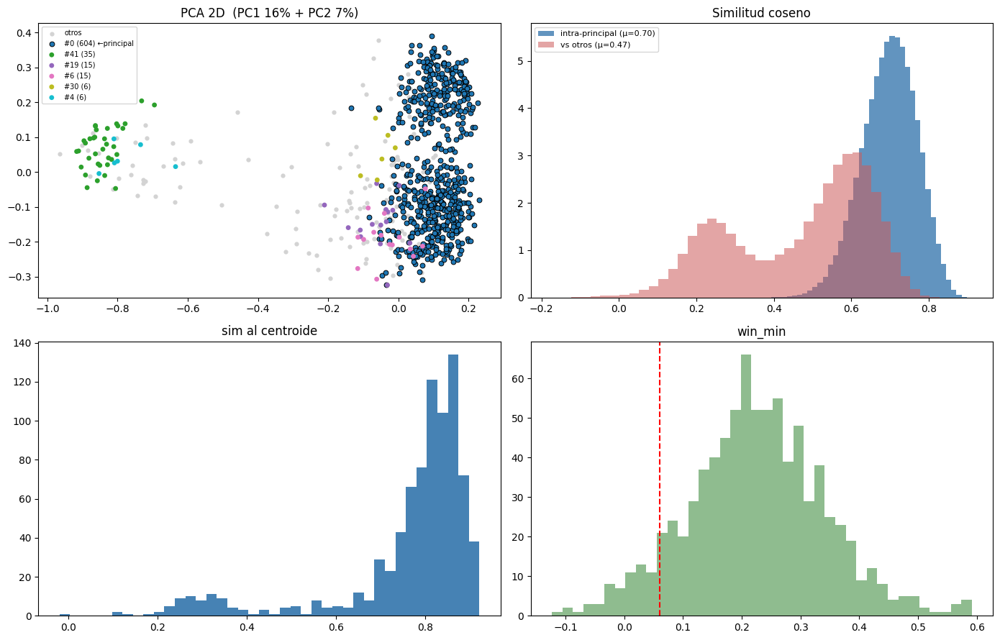


A) BANDA DE OVERLAP → ¿dos voces mezcladas?
frag_0745  6.8s  sim=0.523  win=0.000


frag_0619  6.2s  sim=0.716  win=0.001


frag_0180  7.9s  sim=0.871  win=0.003


frag_0819  6.8s  sim=0.796  win=0.004



B) PEORES DENTRO DEL CLÚSTER → ¿son locutor principal?
frag_0629  3.0s  sim=0.659  win=0.167


...

frag_0362  4.0s  sim=0.724  win=0.165



C) MEJORES FUERA DEL CLÚSTER → ¿tirados por error?
frag_0770  9.2s  sim=0.819  win=-0.010


frag_0121  5.3s  sim=0.814  win=0.290


frag_0119  3.3s  sim=0.813  win=0.436


frag_0423  5.4s  sim=0.806  win=0.099


In [6]:
# conjunto completo
paths = sorted(FRAG_DIR.glob("*.wav")) + sorted(OTHER_DIR.glob("*.wav"))
dx = pd.DataFrame({"id": [p.stem for p in paths], "path": [str(p) for p in paths]})

meta = None
for src in (WORK_DIR / "manifest_frags.csv", CLUSTER_CSV):
    if src.exists():
        meta = pd.read_csv(src).set_index("id"); break
if meta is None and "frags" in globals():
    meta = frags.set_index("id")
for c in ("dur", "start", "region"):
    dx[c] = dx["id"].map(meta[c]) if (meta is not None and c in meta.columns) else np.nan
if dx.dur.isna().any():
    m = dx.dur.isna()
    dx.loc[m, "dur"] = [sf.info(p).duration for p in dx.loc[m, "path"]]

print(f"{len(dx)} frags | {len(list(FRAG_DIR.glob('*.wav')))} en fragments/, "
      f"{len(list(OTHER_DIR.glob('*.wav')))} en other/")

# embeddings + overlap, cacheados por id
ECAPA_DEVICE = "cuda:0" if DEVICE == "cuda" else "cpu"
enc = EncoderClassifier.from_hparams(
    source="speechbrain/spkrec-ecapa-voxceleb",
    savedir=str(WORK_DIR / "ecapa_model"), run_opts={"device": ECAPA_DEVICE})
enc.mods.to(ECAPA_DEVICE)

@torch.no_grad()
def _emb_win(path, win=1.2, hop=0.75, sr=16000):
    """Devuelve (embedding global, win_min)."""
    y, _ = librosa.load(str(path), sr=sr, mono=True)
    def _n(t):
        e = enc.encode_batch(t.to(ECAPA_DEVICE))
        return torch.nn.functional.normalize(e.squeeze(1), dim=-1)

    g = _n(torch.from_numpy(y).unsqueeze(0))[0].cpu().numpy()
    W, H = int(win*sr), int(hop*sr)
    if len(y) < 2*W:
        return g, np.nan
    wins = np.stack([y[a:a+W] for a in range(0, len(y)-W+1, H)])
    V = _n(torch.from_numpy(wins)).cpu().numpy()
    return g, float((V @ V.T)[np.triu_indices(len(V), k=1)].min())

cache = {}
if EMB_CACHE.exists() and not FORCE_EMB:
    z = np.load(EMB_CACHE, allow_pickle=True)
    cache = {i: (e, w) for i, e, w in zip(z["ids"], z["E"], z["win"])}
falta = [r for _, r in dx.iterrows() if r["id"] not in cache]
if falta:
    for r in tqdm(falta, desc="ECAPA"):
        cache[r["id"]] = _emb_win(r["path"])
    np.savez(EMB_CACHE, ids=np.array(list(cache)),
             E=np.stack([v[0] for v in cache.values()]),
             win=np.array([v[1] for v in cache.values()]))
E = np.stack([cache[i][0] for i in dx["id"]])
dx["win_min"] = [cache[i][1] for i in dx["id"]]

# ancla + HC
c = E[(dx.dur >= dx.dur.quantile(.6)).values].mean(0); c /= np.linalg.norm(c)
for _ in range(5):
    s = E @ c; c = E[s >= np.percentile(s, 10)].mean(0); c /= np.linalg.norm(c)
dx["sim"] = E @ c

lab  = AgglomerativeClustering(n_clusters=None, distance_threshold=SPK_CLUSTER_DIST,
                               metric="cosine", linkage="average").fit_predict(E)
main = int(np.bincount(lab).argmax())
keep = (lab == main) & (dx.win_min.fillna(1.0).to_numpy() >= OVERLAP_MIN)
print(f"\ndist={SPK_CLUSTER_DIST} → {lab.max()+1} clústeres | principal #{main}="
      f"{(lab==main).sum()} | tras overlap≥{OVERLAP_MIN}: {keep.sum()} "
      f"({dx.dur[keep].sum()/60:.1f} min)")

# barridos
print("\ndist  clúst  princ    min  sim_p5")
for d in (0.25, 0.30, 0.35, 0.40, 0.45, 0.50):
    l = AgglomerativeClustering(n_clusters=None, distance_threshold=d,
                                metric="cosine", linkage="average").fit_predict(E)
    m = int(np.bincount(l).argmax())
    print(f"{d:.2f}  {l.max()+1:5d}  {(l==m).sum():5d}  {dx.dur[l==m].sum()/60:5.1f}"
          f"   {np.percentile(dx.sim[l==m],5):.3f}")
print("\novlp  frags    min")
for ov in (0.05, 0.08, 0.10, 0.15):
    k = (lab == main) & (dx.win_min.fillna(1.0).to_numpy() >= ov)
    print(f"{ov:.2f}  {k.sum():5d}  {dx.dur[k].sum()/60:5.1f}")

# gráficas
Xm = E[lab == main]
proj = PCA(2, random_state=42).fit(E)
P, evr = proj.transform(E), proj.explained_variance_ratio_
sims_in = cosine_similarity(Xm)[np.triu_indices(len(Xm), k=1)]

fig, ax = plt.subplots(2, 2, figsize=(14, 9)); ax = ax.ravel()

top = [k for k, _ in Counter(lab).most_common(6)]
ax[0].scatter(*P[~np.isin(lab, top)].T, c="lightgray", s=12, label="otros")
for col, k in zip(plt.cm.tab10(np.linspace(0, 1, len(top))), top):
    m = lab == k
    ax[0].scatter(*P[m].T, color=[col], s=24,
                  edgecolors=("k" if k == main else "none"), linewidths=.7,
                  label=f"#{k} ({m.sum()})" + (" ←principal" if k == main else ""))
ax[0].set_title(f"PCA 2D  (PC1 {evr[0]*100:.0f}% + PC2 {evr[1]*100:.0f}%)")
ax[0].legend(fontsize=7)

ax[1].hist(sims_in, bins=40, color="steelblue", density=True, alpha=.85,
           label=f"intra-principal (μ={sims_in.mean():.2f})")
if (lab != main).sum() >= 2:
    fuera = cosine_similarity(Xm, E[lab != main]).ravel()
    ax[1].hist(fuera, bins=40, color="indianred", density=True, alpha=.55,
               label=f"vs otros (μ={fuera.mean():.2f})")
ax[1].set_title("Similitud coseno"); ax[1].legend(fontsize=8)

ax[2].hist(dx.sim, bins=40, color="steelblue"); ax[2].set_title("sim al centroide")

ax[3].hist(dx.win_min.dropna(), bins=40, color="darkseagreen")
ax[3].axvline(OVERLAP_MIN, color="r", ls="--"); ax[3].set_title("win_min")

plt.tight_layout()
for _ext in ("png", "pdf"):    # exporta la figura para el artículo (LaTeX)
    plt.savefig(WORK_DIR / f"cluster_pca.{_ext}", dpi=200, bbox_inches="tight")
plt.show()

# ═══ AUDIOS A VALIDAR ═══
def escuchar(sel, titulo):
    print(f"\n{'='*60}\n{titulo}\n{'='*60}")
    for _, r in sel.iterrows():
        print(f"{r['id']}  {r['dur']:.1f}s  sim={r['sim']:.3f}  win={r['win_min']:.3f}")
        display(Audio(r["path"]))

escuchar(dx[dx.win_min.between(0, .20)].nsmallest(N_LISTEN, "win_min"),
         "A) BANDA DE OVERLAP → ¿dos voces mezcladas?")
escuchar(dx[keep].nsmallest(N_LISTEN, "sim"),
         "B) PEORES DENTRO DEL CLÚSTER → ¿son locutor principal?")
escuchar(dx[~keep & (lab != main)].nlargest(N_LISTEN, "sim"),
         "C) MEJORES FUERA DEL CLÚSTER → ¿tirados por error?")

In [9]:
FRAG_DIR.mkdir(parents=True, exist_ok=True)
OTHER_DIR.mkdir(parents=True, exist_ok=True)
# 1) Restaura: devuelve TODO a fragments/ para que el estado no dependa de corridas previas
n_back = 0
for p in list(OTHER_DIR.glob("*.wav")):
    shutil.move(str(p), str(FRAG_DIR / p.name)); n_back += 1

# 2) Aplica el filtro decidido en el dry run
dx["speaker"], dx["is_main"] = lab, keep
dx["path"] = [str(FRAG_DIR / f"{i}.wav") for i in dx["id"]]
dx.to_csv(WORK_DIR / "cluster_results_ecapa.csv", index=False)

n_out = 0
for i in dx.loc[~keep, "id"]:
    src = FRAG_DIR / f"{i}.wav"
    if src.exists():
        shutil.move(str(src), str(OTHER_DIR / src.name)); n_out += 1

frags = dx[keep].reset_index(drop=True)
print(f"restaurados {n_back} → filtrados: {len(frags)} en fragments/, "
      f"{n_out} en fragments_other/ | {frags.dur.sum()/60:.1f} min")

restaurados 0 → filtrados: 563 en fragments/, 265 en fragments_other/ | 57.8 min


In [10]:
NO_SAMPLES_VIS = 3

others = dx[~dx["is_main"]]
if len(others) == 0:
    print("No hay fragmentos descartados.")
else:
    print(f"── Muestras DESCARTADAS ({len(others)} en fragments_other/) ──")
    for _, r in others.sample(min(NO_SAMPLES_VIS, len(others))).iterrows():
        p = OTHER_DIR / f"{r['id']}.wav"
        print(f"{r['id']}  sim={r['sim']:.3f}  win={r['win_min']:.3f}")
        display(Audio(str(p))) if p.exists() else print(f"  (no encontrado: {p.name})")

print(f"\n── Muestras del locutor PRINCIPAL ({len(frags)}) ──")
for _, r in frags.sample(min(NO_SAMPLES_VIS, len(frags))).iterrows():
    print(f"{r['id']}  sim={r['sim']:.3f}  win={r['win_min']:.3f}")
    display(Audio(str(r["path"])))

── Muestras DESCARTADAS (265 en fragments_other/) ──
frag_0736  sim=0.269  win=0.296


frag_0397  sim=0.829  win=0.060


frag_0288  sim=0.760  win=0.578



── Muestras del locutor PRINCIPAL (563) ──
frag_0402  sim=0.876  win=0.182


frag_0082  sim=0.904  win=0.224


frag_0540  sim=0.881  win=0.217


En algunas ejecuciones quedan fragmentos del locutor principal fuera del clúster (falsos
descartes). Es un intercambio aceptable: un clustering **restrictivo** pierde algunos audios
válidos, pero da más seguridad de que ningún otro locutor contamine el dataset usado por los
modelos de generación de voz.

## 4. Referencia de voz dedicada (bucket *referencia*)

**Los backends que clonan (XTTS) mejoran con una referencia larga y limpia.** Por eso se construye
un audio de referencia **dedicado** (~`REF_LEN_SEC` s) concatenando los mejores fragmentos largos
del locutor (alta similitud al centroide), y esos fragmentos se **excluyen de train/val/test** para
no contaminar la evaluación. Este audio es la **entrada fija** de la clonación en inferencia.

- `SPEAKER_REF`: un único WAV concatenado (en esta corrida: 4 clips, ~38 s)

In [12]:
XTTS_SR = TARGET_SR

cand = frags[frags.dur.between(4, 10) & (frags.sim >= frags.sim.median())].copy()
cand["sesion"] = np.where(cand.start.between(4800, 6600), "B", "A")
dom = cand.sesion.value_counts().idxmax()
cand = cand[cand.sesion == dom].sort_values("start")

cand["blk"] = pd.qcut(np.arange(len(cand)), min(15, len(cand)), labels=False)   # 15, no 8
picks = cand.sort_values("dur", ascending=False).groupby("blk").head(1).sort_values("start")

EXCLUIR = ["frag_0830"]                                    # ← ids con voces ajenas
picks = picks[~picks.id.isin(EXCLUIR)]

sel, acc = [], 0.0
for _, r in picks.iterrows():
    sel.append(r); acc += r["dur"]
    if acc >= REF_LEN_SEC: break
ref_df = pd.DataFrame(sel)
REF_IDS = set(ref_df["id"])

# concatenación con crossfade y normalización
XF  = int(0.015 * XTTS_SR)
fin = np.linspace(0, 1, XF); fout = fin[::-1]
rms = lambda y: y * (10**(-23/20) / (np.sqrt(np.mean(y**2)) + 1e-9))

out = None
for p in ref_df["path"]:
    y = rms(librosa.load(p, sr=XTTS_SR)[0])
    out = y if out is None else np.concatenate(
        [out[:-XF], out[-XF:]*fout + y[:XF]*fin, y[XF:]])
out = out / (np.abs(out).max() + 1e-9) * 0.95

SPEAKER_REF = WORK_DIR / "speaker_ref.wav"
sf.write(SPEAKER_REF, out, XTTS_SR)
print(f"referencia: {len(out)/XTTS_SR:.1f}s @ {XTTS_SR}Hz, {len(ref_df)} clips")

# validación contra el centroide del dry run
sr_emb = _emb_win(SPEAKER_REF)[0]
print(f"ref vs centroide: {float(sr_emb @ c):.3f} | intra p50/p90:",
      np.round(np.percentile(frags.sim, [50, 90]), 3))

display(Audio(str(SPEAKER_REF)))
print(f"\n── clips que entraron ({len(ref_df)}) ──")
for _, r in ref_df.iterrows():
    print(f"{r['id']}  {r['dur']:.1f}s")
    display(Audio(r["path"]))

referencia: 38.3s @ 22050Hz, 4 clips
ref vs centroide: 0.953 | intra p50/p90: [0.84  0.889]



── clips que entraron (4) ──
frag_0049  9.9s


frag_0082  9.3s


frag_0124  9.6s


frag_0153  9.6s


La limpieza y separación de locutores es compleja, sobre todo con voces solapadas o ruido dentro
del mismo fragmento. Lo más crítico para la reconstrucción es que el **audio de referencia** (el
que se usa en inferencia) sea lo más puro posible y capte bien al locutor; vale la pena validarlo
manualmente (escucharlo). En el fine-tuning es menos grave: el volumen de muestras diluye el
efecto de algún fragmento malo.

## 5. Etiquetado con STT (Whisper) → dataset `(audio, texto)`

Cada fragmento se transcribe con **faster-whisper** (`large-v3`, beam search de 5). El texto
resultante es la **etiqueta** del par `(audio, texto)`: alimenta el fine-tuning y es el texto de
entrada en la reconstrucción. El mismo modelo se reutiliza después para el WER *round-trip*.

Este etiquetado solo se necesita para **entrenar y comparar** los backends; una vez elegido el
modelo, la inferencia es directa: texto → audio (ver celdas finales).

In [13]:
stt = WhisperModel("large-v3", device=DEVICE,
                   compute_type="float16" if DEVICE == "cuda" else "int8")

def transcribe(path, lang=LANGUAGE):
    segs, info = stt.transcribe(
        str(path), language=lang, beam_size=5, vad_filter=False,
        condition_on_previous_text=False,   # evita bucles de repetición
        temperature=0.0,                    # determinista
    )
    text = " ".join(s.text.strip() for s in segs).strip()
    return text, info.language

frags["text"] = [transcribe(p)[0] for p in tqdm(frags["path"], desc="STT")]
frags = frags[frags["text"].str.len() >= 3].reset_index(drop=True)
frags["n_words"] = frags["text"].str.split().apply(len)

# tasa de habla: delata transcripciones incompletas o alucinadas
frags["wps"] = (frags.n_words / frags.dur).round(2)
print(f"etiquetados: {len(frags)} | wps p5/p50/p95:",
      np.round(np.percentile(frags.wps, [5, 50, 95]), 2))

sosp = frags[(frags.wps < 1.5) | (frags.wps > 5.0)]
print(f"sospechosos: {len(sosp)}")
display(sosp[["id", "dur", "n_words", "wps", "text"]].head(15))

STT:   0%|          | 0/563 [00:00<?, ?it/s]

etiquetados: 563 | wps p5/p50/p95: [2.14 3.25 4.33]
sospechosos: 13


,id,dur,n_words,wps,text
11,frag_0036,4.47,23,5.15,¿Ok? Y esto es lo que casi en esta clase es lo...
30,frag_0070,8.25,12,1.45,Y ese es el problema. ¿Es verdad que las LSTMs...
56,frag_0110,6.07,31,5.11,Que todo mundo se vea contra todo mundo. Y la ...
87,frag_0170,5.47,7,1.28,para poder entender recordemos lo que es
130,frag_0239,3.21,17,5.30,"Ya le vamos a poner una letra, pero lo que imp..."
208,frag_0342,5.64,29,5.14,"Cojo pizza, le sumo y digo, ah, este es del em..."
253,frag_0401,5.56,31,5.58,"Y ese match, ¿qué va a hacer? Va a tratar de b..."
309,frag_0480,6.35,33,5.20,"El heavy, ¿no es cierto? Yo quiero buscar heav..."
329,frag_0504,3.84,20,5.21,Y la misma idea voy a aplicar para el Key y el...
367,frag_0547,5.95,8,1.34,Ya tenemos nuestras matrices Query Key y Value.


## 6. Splits: train / val / test y manifests

Del resto de fragmentos (**sin la referencia**) se hace un split reproducible **por región de
VAD**: los trozos que salieron de la misma región (misma frase larga) van al mismo split, para que
no haya fuga de contenido entre train y test.

- **train** (`TRAIN_FRAC`) → **solo** para el fine-tuning de XTTS (`xtts_ft`).
- **val** (`VAL_FRAC`) → selección del checkpoint del fine-tuning.
- **test** (`TEST_FRAC`) → **solo evaluación final**, igual para todos los backends.

Así no hay fuga: nada de lo que se evalúa se usó para entrenar ni como referencia.

In [14]:
pool = frags[~frags["id"].isin(REF_IDS)].reset_index(drop=True)

# split por REGIÓN, no por fila: trozos de la misma frase no deben cruzar splits
if "region" in pool.columns:
    regs = pool.region.unique()
    rng = np.random.default_rng(42); rng.shuffle(regs)
    n_tr = int(len(regs) * TRAIN_FRAC); n_va = int(len(regs) * VAL_FRAC)
    grupos = {"train": set(regs[:n_tr]), "val": set(regs[n_tr:n_tr+n_va]),
              "test": set(regs[n_tr+n_va:])}
    train_df = pool[pool.region.isin(grupos["train"])].reset_index(drop=True)
    val_df   = pool[pool.region.isin(grupos["val"])].reset_index(drop=True)
    test_df  = pool[pool.region.isin(grupos["test"])].reset_index(drop=True)
    print(f"split por región: {len(regs)} regiones")
else:
    pool = pool.sample(frac=1.0, random_state=42).reset_index(drop=True)
    n = len(pool); n_tr = int(n*TRAIN_FRAC); n_va = int(n*VAL_FRAC)
    train_df = pool.iloc[:n_tr].reset_index(drop=True)
    val_df   = pool.iloc[n_tr:n_tr+n_va].reset_index(drop=True)
    test_df  = pool.iloc[n_tr+n_va:].reset_index(drop=True)
    print("⚠️ sin columna 'region' → split por fila (test posiblemente optimista)")

for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    df.to_csv(WORK_DIR / f"{name}.csv", index=False)
ref_df.to_csv(WORK_DIR / "reference.csv", index=False)

print(f"ref: {len(ref_df)} | train: {len(train_df)} | val: {len(val_df)} | test: {len(test_df)}")
print(f"minutos → train {train_df.dur.sum()/60:.1f} | val {val_df.dur.sum()/60:.1f} "
      f"| test {test_df.dur.sum()/60:.1f}")
assert REF_IDS.isdisjoint(set(pool['id'])), "fuga: la referencia no debe estar en los splits"

split por región: 519 regiones
ref: 4 | train: 442 | val: 45 | test: 72
minutos → train 44.6 | val 4.6 | test 7.9


### 6b. Checkpoint del pipeline: reanudar desde los datos preprocesados

Esta celda **recarga todo desde disco**
(manifests CSV, referencia de voz y, si existe, el checkpoint del fine-tuning) sin repetir
VAD/STT.


In [ ]:
train_df = pd.read_csv(WORK_DIR / "train.csv")
val_df   = pd.read_csv(WORK_DIR / "val.csv")
test_df  = pd.read_csv(WORK_DIR / "test.csv")
SPEAKER_REF = WORK_DIR / "speaker_ref.wav"

print("train:", len(train_df), "| val:", len(val_df), "| test:", len(test_df))
assert SPEAKER_REF.exists(), "falta speaker_ref.wav"
assert Path(train_df["path"].iloc[0]).exists(), "faltan los wav de fragments/ en disco"

# Reanuda también el fine-tuning: si hay un checkpoint entrenado en disco, se usa para que el
# backend xtts_ft se registre sin re-entrenar (§7 escribe en xtts_ft_run/; Colab lo dejaba en ./)
if not globals().get("XTTS_FT_CKPT"):
    _cands = [d for base in (WORK_DIR / "xtts_ft_run", Path(".")) if base.exists()
              for d in base.iterdir()
              if d.is_dir() and d.name.startswith("xtts_ft") and (d / "best_model.pth").exists()]
    if _cands:
        _run = max(_cands, key=os.path.getmtime)
        from huggingface_hub import hf_hub_download
        XTTS_FT_CKPT = {"checkpoint": str(_run / "best_model.pth"),
                        "config":     str(_run / "config.json"),
                        "vocab":      hf_hub_download("coqui/XTTS-v2", "vocab.json")}
        print("checkpoint de fine-tuning encontrado →", XTTS_FT_CKPT["checkpoint"])
    else:
        print("sin checkpoint de fine-tuning en disco ")


## 7. Fine-tuning liviano de XTTS (`xtts_ft`)

Además del zero-shot, se afina XTTS sobre el `train` set para comparar *zero-shot* vs
*fine-tuning* con las mismas métricas. Es **liviano**: se parte del checkpoint preentrenado y se
afina **solo el GPT** (el módulo que modela prosodia/pronunciación); DVAE, encoders de locutor y
vocoder quedan congelados para no degradar la calidad de audio con pocos datos.

- **Entrada:** pares `(audio, texto)` de `train` (nunca val/test) + ficheros base de XTTS v2.
- **Salida:** checkpoints en `xtts_ft_run/` que luego carga el backend `xtts_ft`.
- **Receta:** la oficial de Coqui (`train_gpt_xtts`): AdamW, lr 5e-6, MultiStepLR (×0.5 en las
  épocas-milestone), batch 16, `XTTS_FT_EPOCHS` épocas.

> Algún argumento de `GPTArgs` puede variar según la versión de `coqui-tts`; si cambia, ajusta esa
> línea.

### 7a. XTTS v2 por dentro (resumen)

XTTS v2 **no** es un TTS clásico (texto → mel → vocoder, estilo Tacotron): es un **"LLM de
audio"** que trata la síntesis como *modelado de lenguaje* sobre **tokens discretos de audio**.
Basta con ubicar sus cuatro módulos y qué hace cada uno — el detalle (dimensiones, flujos de
entrenamiento/inferencia y por qué) está en el artículo `proy_final.tex`:

```text
              (una vez por locutor)                                 (por cada frase)
SPEAKER_REF ─┬─► mel 80 ─► ConditioningEncoder + Perceiver ─► 32 latentes × 1024 ──┐
             └─► SpeakerEncoder (16 kHz) ─► embedding 512-d ────────────────┐      │
texto ─► limpieza + BPE (vocab 6681, prefijo [es]) ─► ≤ 402 tokens ─────────┤      │
                                                                            ▼      ▼
                  GPT-2 (30 capas, d=1024) ─► tokens de audio (≤605, vocab 1026)
                                       │ pasan sus estados ocultos 1024-d (no los códigos)
                                       └─► HiFi-GAN ─► wav 24 kHz
```

- **Tokenizador de texto (BPE):** texto → subunidades (sin fonemas); el GPT aprende la
  pronunciación de los subtokens.
- **Encoders de la referencia:** convierten `SPEAKER_REF` en (a) 32 latentes que se anteponen a la
  secuencia del GPT (el "timbre" que imita al generar) y (b) un embedding de 512-d que condiciona
  al vocoder.
- **DVAE (VQ-VAE):** el "BPE del audio": discretiza el mel en tokens (~46 ms cada uno). **Solo se
  usa en entrenamiento**, para fabricar los tokens objetivo del GPT.
- **GPT-2 autorregresivo (el corazón, ~443 M):** recibe `[latentes de locutor]+[texto]` y predice
  los tokens de audio uno a uno (con temperatura → no es 100 % determinista). Texto y audio
  tienen tablas de embedding y posicionales *propias* (posiciones reiniciadas en 0 por segmento,
  de ahí los topes independientes de 402/605 tokens); los 32 latentes entran *sin* posicional
  (son un conjunto sin orden temporal). **En el fine-tuning
  solo se entrena este módulo** (cross-entropy sobre tokens); por eso el ajuste es "liviano".
- **Decoder HiFi-GAN:** toma los **estados ocultos** del GPT (no los códigos discretos, que
  pierden demasiada información) y sintetiza la onda a 24 kHz en una sola pasada.

Los argumentos de la celda de fine-tuning salen del **recipe oficial** y del `config.json` del
modelo: `max/min_conditioning_length` = trozo de referencia de 3–6 s tomado del propio audio de
train, `max_wav_length` ≈ 11.6 s, `gpt_num_audio_tokens=1026` (codebook 1024 + start/stop), etc.

Referencias: [recipe oficial](https://github.com/idiap/coqui-ai-TTS/blob/main/recipes/ljspeech/xtts_v2/train_gpt_xtts.py) ·
[`config.json` de XTTS-v2](https://huggingface.co/coqui/XTTS-v2/blob/main/config.json) ·
[docs XTTS](https://docs.coqui.ai/en/latest/models/xtts.html) ·
[checkpoints](https://huggingface.co/coqui/XTTS-v2/tree/main)

In [15]:
vis_m = TTS("tts_models/multilingual/multi-dataset/xtts_v2").to(DEVICE)

In [18]:
model = vis_m.synthesizer.tts_model      # el Xtts (nn.Module)
summary(model, depth=4)              # sin input_size/input_data

Layer (type:depth-idx)                                                 Param #
Xtts                                                                   --
├─GPT: 1-1                                                             --
│    └─ConditioningEncoder: 2-1                                        --
│    │    └─Conv1d: 3-1                                                82,944
│    │    └─Sequential: 3-2                                            --
│    │    │    └─AttentionBlock: 4-1                                   4,200,448
│    │    │    └─AttentionBlock: 4-2                                   4,200,448
│    │    │    └─AttentionBlock: 4-3                                   4,200,448
│    │    │    └─AttentionBlock: 4-4                                   4,200,448
│    │    │    └─AttentionBlock: 4-5                                   4,200,448
│    │    │    └─AttentionBlock: 4-6                                   4,200,448
│    └─Dropout1d: 2-2                                        

In [19]:
print(vis_m.synthesizer.tts_model.config)   # config real del modelo descargado

XttsConfig(output_path='output', logger_uri=None, run_name='run', project_name=None, run_description='🐸Coqui trainer run.', print_step=25, plot_step=100, model_param_stats=False, wandb_entity=None, dashboard_logger='tensorboard', save_on_interrupt=True, log_model_step=None, save_step=10000, save_n_checkpoints=5, save_checkpoints=True, save_all_best=False, save_best_after=10000, target_loss=None, print_eval=False, test_delay_epochs=0, run_eval=True, run_eval_steps=None, distributed_backend='nccl', distributed_url='tcp://localhost:54321', mixed_precision=False, precision='fp16', epochs=1000, batch_size=32, eval_batch_size=16, grad_clip=0.0, scheduler_after_epoch=True, lr=0.001, optimizer='radam', optimizer_params=None, lr_scheduler=None, lr_scheduler_params={}, use_grad_scaler=False, allow_tf32=False, cudnn_enable=True, cudnn_deterministic=False, cudnn_benchmark=False, training_seed=54321, model='xtts', num_loader_workers=0, num_eval_loader_workers=0, use_noise_augment=False, audio=XttsA

In [22]:
# Milestones del lr scheduler del fine-tuning.
# Con scheduler_after_epoch=True (default del Trainer), MultiStepLR avanza una vez por ÉPOCA:
# los milestones se expresan en épocas → lr×0.5 al 50 % y al 80 % del entrenamiento.
# Batch size de 16 para no sobrecargar GPU.

FT_BATCH_SIZE   = 16
steps_per_epoch = math.ceil(len(train_df) / FT_BATCH_SIZE)
total_steps     = steps_per_epoch * XTTS_FT_EPOCHS
milestones      = [int(XTTS_FT_EPOCHS * 0.5), int(XTTS_FT_EPOCHS * 0.8)]   # p. ej. [5, 8]
print("steps/época:", steps_per_epoch, "| total_steps:", total_steps,
      "| milestones (épocas):", milestones)


steps/época: 28 | total_steps: 420 | milestones (épocas): [7, 12]


In [23]:
XTTS_FT_CKPT = None   # se rellena si se entrena; el backend xtts_ft se registra solo si existe
FT_HISTORY   = {"epoch": [], "train_loss": [], "val_loss": []}   # loss por época (para el gráfico)



# Callback: guarda la loss media de train y val al final de cada época
def _pick_loss(avg_values):
    if not avg_values:
        return None
    for k in ("avg_loss", "avg_total_loss", "loss"):      # preferimos la loss total
        if k in avg_values:
            return float(avg_values[k])
    for k, v in avg_values.items():                        # si no, la 1ª que contenga 'loss'
        if "loss" in k:
            try: return float(v)
            except Exception: pass
    return None

def _on_epoch_end(trainer, *_):
    tr = _pick_loss(getattr(getattr(trainer, "keep_avg_train", None), "avg_values", {}))
    va = _pick_loss(getattr(getattr(trainer, "keep_avg_eval",  None), "avg_values", {}))
    FT_HISTORY["epoch"].append(getattr(trainer, "epochs_done", len(FT_HISTORY["epoch"]) + 1))
    FT_HISTORY["train_loss"].append(tr)
    FT_HISTORY["val_loss"].append(va)

# 1) Datos en el formato que espera el GPTTrainer (lista de dicts); SOLO train/val, nunca test
def _to_samples(df):
    return [{"text": r["text"], "audio_file": r["path"], "speaker_name": "me",
              "language": (LANGUAGE or "es"), "root_path": str(WORK_DIR)}
            for _, r in df.iterrows()]
train_samples, eval_samples = _to_samples(train_df), _to_samples(val_df)

# 2) Ficheros base de XTTS v2 (GPT, DVAE, mel_stats, tokenizer) desde HuggingFace
REPO = "coqui/XTTS-v2"
dvae_ckpt = hf_hub_download(REPO, "dvae.pth")
mel_stats = hf_hub_download(REPO, "mel_stats.pth")
vocab     = hf_hub_download(REPO, "vocab.json")
xtts_ckpt = hf_hub_download(REPO, "model.pth")

# 3) Config obtenida del pretraining usado de XTTS
# max_conditioning_length_sec= 132300/22050 = 6 seg
# min_conditioning_length_sec= 66150/22050 = 3 seg
# max_wav_lenght_sec= 255995/22050 = 11.61 seg

model_args = GPTArgs(
    max_conditioning_length=132300, min_conditioning_length=66150,
    max_wav_length=255995, max_text_length=200,
    mel_norm_file=mel_stats, dvae_checkpoint=dvae_ckpt,
    xtts_checkpoint=xtts_ckpt, tokenizer_file=vocab,
    gpt_num_audio_tokens=1026, gpt_start_audio_token=1024, gpt_stop_audio_token=1025,
    gpt_use_masking_gt_prompt_approach=True, gpt_use_perceiver_resampler=True,
)

# 4) Configuración del trainer. Solamente se modifica los lr scheduler params, batch size , lr y XTTS_FT_EPOCHS
# Guardar 3 checkpoints cada 2 epocas con save_step y save_n_checkpoints
audio_cfg = XttsAudioConfig(sample_rate=22050, dvae_sample_rate=22050, output_sample_rate=24000)
FT_OUT = WORK_DIR / "xtts_ft_run"
cfg = GPTTrainerConfig(
    output_path=str(FT_OUT), model_args=model_args, audio=audio_cfg,
    run_name="xtts_ft", project_name="myvoice",
    epochs=XTTS_FT_EPOCHS, batch_size=FT_BATCH_SIZE, eval_batch_size=FT_BATCH_SIZE, batch_group_size=48,
    num_loader_workers=2, print_step=25, save_step=steps_per_epoch*2, save_n_checkpoints=3,
    run_eval=True, optimizer="AdamW",
    optimizer_params={"betas": [0.9, 0.96], "eps": 1e-8, "weight_decay": 1e-1},
    lr=5e-6, lr_scheduler="MultiStepLR",
    lr_scheduler_params={"milestones": milestones, "gamma": 0.5},
)
# save_best_after de 0 para fine tuning
cfg.save_best_after = 0
model = GPTTrainer.init_from_config(cfg)
_t_args = [TrainerArgs(restore_path=None, skip_train_epoch=False), cfg]
_t_kw = dict(output_path=str(FT_OUT), model=model,
              train_samples=train_samples, eval_samples=eval_samples)
try:                                        # registra el callback si la versión lo soporta
    trainer = Trainer(*_t_args, callbacks={"on_epoch_end": _on_epoch_end}, **_t_kw)
except TypeError:
    print("[aviso] esta versión de trainer no acepta callbacks; se leerá la loss de TensorBoard")
    trainer = Trainer(*_t_args, **_t_kw)
trainer.fit()

# 4) Localiza el mejor checkpoint para que lo cargue el backend xtts_ft
run_dir = max((p for p in FT_OUT.iterdir() if p.is_dir()), key=os.path.getmtime)
XTTS_FT_CKPT = {"checkpoint": str(run_dir / "best_model.pth"),
                "config": str(run_dir / "config.json"), "vocab": vocab}
print("fine-tuning listo →", XTTS_FT_CKPT["checkpoint"])


 > Training Environment:
 | > Backend: Torch
 | > Mixed precision: False
 | > Precision: float32
 | > Current device: 0
 | > Num. of GPUs: 1
 | > Num. of CPUs: 224
 | > Num. of Torch Threads: 4
 | > Torch seed: 1
 | > Torch CUDNN: True
 | > Torch CUDNN deterministic: False
 | > Torch CUDNN benchmark: False
 | > Torch TF32 MatMul: True
 > Start Tensorboard: tensorboard --logdir=tts_dataset/xtts_ft_run/xtts_ft-July-22-2026_07+29PM-0000000

 > Model has 518442047 parameters

 > EPOCH: 0/14
 --> tts_dataset/xtts_ft_run/xtts_ft-July-22-2026_07+29PM-0000000

 > TRAINING (2026-07-22 19:29:59) 

   --> TIME: 2026-07-22 19:30:00 -- STEP: 0/27 -- GLOBAL_STEP: 0
     | > current_lr: 5e-06  (5e-06)
     | > loss_text_ce: 0.025624100118875504  (0.025624100118875504)
     | > loss_mel_ce: 4.52245569229126  (4.52245569229126)
     | > loss: 4.548079967498779  (4.548079967498779)
     | > grad_norm: 0.0  (0.0)
     | > step_time: 0.5928  (0.5927984714508057)
     | > loader_time: 0.6464  (0.6464014053

fine-tuning listo → tts_dataset/xtts_ft_run/xtts_ft-July-22-2026_07+29PM-0000000/best_model.pth


### 7b. Curva de loss del fine-tuning (train vs val)

`train` y `val` en la misma gráfica frente a la época (capturadas por un *callback* del `Trainer`;
si la versión no soporta callbacks, se leen de TensorBoard). Interpretación rápida: si `val` se
estanca o sube mientras `train` baja → sobreajuste. Ojo: la loss es entropía cruzada sobre
**tokens**, no una medida perceptual, así que el checkpoint final no se elige aquí sino con el
barrido de métricas (§8). La figura se guarda como `loss_curve.png/pdf` para el artículo.

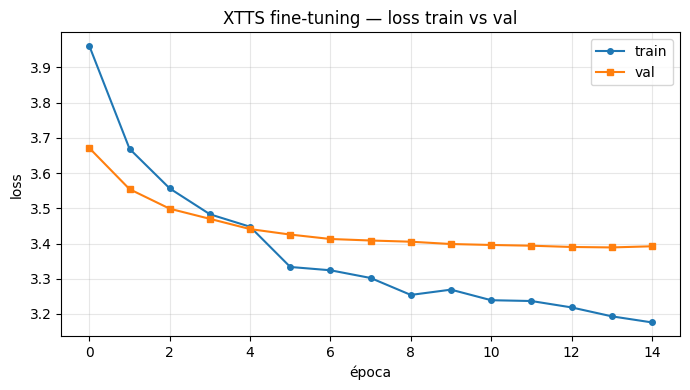

In [24]:
%matplotlib inline

def _tb_loss_curves(run_dir):
    "Fallback: lee las curvas de loss de los eventos de TensorBoard del run de fine-tuning."
    try:
        from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    except Exception:
        return None
    evs = sorted(Path(run_dir).rglob("events.out.tfevents.*"))
    if not evs:
        return None
    acc = EventAccumulator(str(evs[-1].parent)); acc.Reload()
    tags = acc.Tags().get("scalars", [])
    out = {}
    for name, patt in [("train", "train"), ("val", "eval")]:
        tag = next((t for t in tags if "loss" in t.lower() and patt in t.lower()), None)
        if tag:
            out[name] = [(e.step, e.value) for e in acc.Scalars(tag)]
    return out if out.get("train") else None

# 1º intenta el historial del callback (por época); si no existe, TensorBoard (por step)
if FT_HISTORY["epoch"]:
    curves = {"train": [(e, v) for e, v in zip(FT_HISTORY["epoch"], FT_HISTORY["train_loss"]) if v is not None],
              "val":   [(e, v) for e, v in zip(FT_HISTORY["epoch"], FT_HISTORY["val_loss"])   if v is not None]}
    xlab = "época"
else:
    _ckpt = globals().get("XTTS_FT_CKPT")
    curves = _tb_loss_curves(Path(_ckpt["checkpoint"]).parent) if _ckpt else None
    xlab = "step"
    if curves:
        print("historial leído de TensorBoard (eje x = step, no época)")

if curves and curves.get("train"):
    plt.figure(figsize=(7, 4))
    for name, marker in [("train", "o"), ("val", "s")]:
        pts = curves.get(name) or []
        if pts:
            plt.plot([p[0] for p in pts], [p[1] for p in pts],
                     marker=marker, markersize=4, label=name)
    plt.xlabel(xlab); plt.ylabel("loss")
    plt.title("XTTS fine-tuning — loss train vs val")
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    for _ext in ("png", "pdf"):    # exporta la figura para el artículo (LaTeX)
        plt.savefig(WORK_DIR / f"loss_curve.{_ext}", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("sin historial de loss: corre antes la celda de fine-tuning "
          "(o no se encontraron eventos de TensorBoard en el run)")


## 8. Backends de reconstrucción TTS

Todos comparten la **misma firma** `fn(text, out, ref)` (por eso `run_backend` los llama igual y la
comparación es justa), pero **difieren en qué entrada usan de verdad** — sobre todo si usan la
referencia (clonan tu voz) o la ignoran (voz fija → *baseline*).

| Backend | ¿Usa `ref`? (clona) | Entrada real | Salida | Idiomas | Velocidad | Determinista |
|---|---|---|---|---|---|---|
| `xtts`     | ✅ 1 wav 6–20 s+     | texto + `SPEAKER_REF` + idioma | wav 24 kHz | 17 (es, en…) | rápida | bastante |
| `xtts_ft`  | ✅ (+ pesos afinados) | texto + latentes de `SPEAKER_REF` | wav 24 kHz | igual que XTTS | rápida | bastante |
| `bark`     | ❌ ignora `ref`      | texto + `voice_preset` fijo | wav 24 kHz | multi (presets) | lenta | no (muestrea) |

**Detalle de cada uno:**

- **`xtts` (XTTS v2, principal):** DVAE (tokeniza audio) + GPT autorregresivo condicionado por un
  *latente de locutor* (de tu referencia) y los tokens de texto → decoder HiFi-GAN (arquitectura, dimensiones y preprocesamiento interno: ver **§7a**). Entrada:
  `texto + SPEAKER_REF + language`. Clona **zero-shot** (sin tocar pesos). Límite ~250 caracteres.
- **`xtts_ft` (XTTS v2 fine-tuneado):** mismo XTTS pero con el **GPT afinado** sobre tu `train` set
  (ver celda de fine-tuning). Se registra solo si existe el checkpoint. Es la comparación central:
  **zero-shot vs fine-tuning** con las mismas métricas.
- **`bark` (baseline):** GPT texto→tokens semánticos→coarse→fine (EnCodec)→onda. Usa un **preset de
  voz fijo**; **ignora la referencia** (no imita tu voz) → sirve de *control*: su `spk_sim` bajo
  demuestra que el `spk_sim` alto de `xtts`/`xtts_ft` se debe realmente a la clonación.

**Qué esperar en los 3 niveles:** los que clonan (`xtts`, `xtts_ft`) deben dar `spk_sim` **alto**;
el baseline `bark` **bajo** (no clona). En `WER`, los tres son multilingües y deberían andar bien en
español; la diferencia fina la marca el `MCD`, donde `xtts_ft` debería acercarse más al original que
el `xtts` zero-shot si el fine-tuning ayudó.


In [39]:
#Evitar warnings de padding del XTTs zero shot (usa GPT internamente)
transformers.logging.set_verbosity_error()

In [27]:
BACKEND_FNS = {}   # backend -> fn(text, out_path, speaker_ref)
SEED = globals().get("SEED", 42)

# Ajustes de inferencia COMPARTIDOS por xtts y xtts_ft: la UNICA diferencia entre ambos
# debe ser el checkpoint, no estos knobs. Valores recomendados del XttsConfig v2.
XTTS_COND  = dict(gpt_cond_len=30, gpt_cond_chunk_len=4,
                  max_ref_length=30, sound_norm_refs=True)
XTTS_INFER = dict(temperature=0.75, length_penalty=1.0,
                  repetition_penalty=2.0, top_k=50, top_p=0.85,
                  enable_text_splitting=True)

try:
    torch.serialization.add_safe_globals(
        [XttsConfig, XttsAudioConfig, XttsArgs, BaseDatasetConfig])
except Exception:
    pass


def _xtts_fn_from_model(xtts_model):
    # Latentes de SPEAKER_REF una sola vez + inference de bajo nivel con kwargs explicitos
    gpt_cond, spk_emb = xtts_model.get_conditioning_latents(
        audio_path=[str(SPEAKER_REF)], **XTTS_COND)
    sr = xtts_model.config.audio.output_sample_rate
    def fn(text, out, ref=None):
        torch.manual_seed(SEED)
        o = xtts_model.inference(text, (LANGUAGE or "es"), gpt_cond, spk_emb, **XTTS_INFER)
        sf.write(str(out), o["wav"], sr)
    return fn


def _register_xtts():
    m = TTS("tts_models/multilingual/multi-dataset/xtts_v2").to(DEVICE)
    return _xtts_fn_from_model(m.synthesizer.tts_model)


def _register_xtts_ft(ckpt_path=None):
    ckpt = globals().get("XTTS_FT_CKPT")
    if not ckpt:
        raise RuntimeError("no hay checkpoint fine-tuneado; corre la celda de fine-tuning")
    from TTS.tts.models.xtts import Xtts

    # El config.json del run es un GPTTrainerConfig (model_args=GPTArgs), no un XttsConfig:
    # cargarlo dejaria campos de arquitectura con defaults equivocados. Se usa el oficial
    # de v2 y del checkpoint solo se toman los PESOS.
    cfg = XttsConfig()
    cfg.load_json(hf_hub_download("coqui/XTTS-v2", "config.json"))

    model = Xtts.init_from_config(cfg)
    model.load_checkpoint(cfg,
                          checkpoint_path=str(ckpt_path or ckpt["checkpoint"]),
                          vocab_path=ckpt["vocab"],
                          eval=True, use_deepspeed=False)
    model.to(DEVICE)
    return _xtts_fn_from_model(model)


def _register_bark():
    proc  = AutoProcessor.from_pretrained("suno/bark-small")
    model = BarkModel.from_pretrained("suno/bark-small").to(DEVICE)
    preset = f"v2/{(LANGUAGE or 'es')}_speaker_1"
    def fn(text, out, ref=None):   # ref ignorada: Bark no clona
        inp = {k: v.to(DEVICE) for k, v in proc(text, voice_preset=preset).items()}
        arr = model.generate(**inp).cpu().numpy().squeeze()
        sf.write(str(out), arr, model.generation_config.sample_rate)
    return fn


REGISTRY = {"xtts": _register_xtts, "xtts_ft": _register_xtts_ft, "bark": _register_bark}

ACTIVE_BACKENDS = ["xtts", "bark"]
if globals().get("XTTS_FT_CKPT"):
    ACTIVE_BACKENDS.append("xtts_ft")

for b in ACTIVE_BACKENDS:
    try:
        BACKEND_FNS[b] = REGISTRY[b]()
        print("backend listo:", b)
    except Exception as e:
        print(f"[!] no se pudo cargar '{b}': {e}")

backend listo: xtts
backend listo: bark


config.json: 0.00B [00:00, ?B/s]

backend listo: xtts_ft


#### Barrido de checkpoints para hallar el mejor modelo

Una menor loss (`best_model` según val-loss) **no** implica mejor reconstrucción: la loss es
cross-entropy sobre tokens, no similitud percibida. Por eso se sintetiza un subconjunto de **val**
con cada checkpoint guardado y se elige el mejor según las métricas objetivas (spk_sim, WER, MCD,
UTMOS). Se usa val y no test: elegir mirando test lo contaminaría como conjunto final.

Cuatro métricas complementarias (ninguna basta por sí sola):

- **Similitud de locutor** (`spk_sim`, ↑ mejor): coseno entre embeddings de voz (Resemblyzer,
  GE2E) del original y el reconstruido. ¿Suena a la misma persona? (Modelo distinto del ECAPA
  usado en el filtrado, para no evaluar con el mismo criterio con que se limpió.)
- **WER / CER round-trip** (↓ mejor): el audio reconstruido se re-transcribe con Whisper y se
  compara con el texto de entrada. ¿Se entiende lo mismo?
- **MCD** (↓ mejor): distorsión mel-cepstral con alineamiento DTW (usa `pymcd` si está instalado;
  si no, aproximación con MFCC de librosa — el backend elegido se imprime abajo). ¿Se parece
  acústicamente la envolvente espectral?
- **UTMOS** (↑ mejor): MOS de naturalidad **predicho** por un modelo (reference-free). Capta
  artefactos de generación (gallos, cortes, prosodia plana) que las otras tres no ven; también se
  calcula sobre las grabaciones reales como techo de referencia.

In [30]:
encoder = VoiceEncoder(device=DEVICE if DEVICE == "cuda" else "cpu")
_norm = jiwer.Compose([jiwer.ToLowerCase(), jiwer.RemovePunctuation(),
                       jiwer.RemoveMultipleSpaces(), jiwer.Strip()])

def speaker_sim(orig, recon):
    e1 = encoder.embed_utterance(preprocess_wav(orig))
    e2 = encoder.embed_utterance(preprocess_wav(recon))
    return float(np.dot(e1, e2) / (np.linalg.norm(e1) * np.linalg.norm(e2)))

def roundtrip_wer(ref_text, recon_path):
    hyp, _ = transcribe(recon_path)
    if not hyp.strip():
        return 1.0, 1.0, hyp
    ref, hyp_n = _norm(ref_text), _norm(hyp)
    return jiwer.wer(ref, hyp_n), jiwer.cer(ref, hyp_n), hyp

# MCD conmutable: si 'pymcd' está instalado (canónico, WORLD/pysptk) se usa ese;
# si no (p. ej. Windows sin compilador), cae a la aprox. con librosa (MFCC + DTW).
try:
    from pymcd.mcd import Calculate_MCD
    _mcd_tool = Calculate_MCD(MCD_mode="dtw")
    def mcd(orig, recon):
        "MCD canónico (pymcd, mel-cepstrum vía WORLD)."
        return float(_mcd_tool.calculate_mcd(orig, recon))
    MCD_BACKEND = "pymcd (canónico)"
except Exception:
    def _mcep(path, sr=16000, n_mfcc=25):
        "MFCCs sin el coef. 0 (energía) -> (frames, n_mfcc-1)."
        y, _ = librosa.load(path, sr=sr)
        return librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)[1:].T
    def mcd(orig, recon, sr=16000):
        "Aprox. de MCD vía MFCC + DTW (sin pysptk)."
        a, b = _mcep(orig, sr), _mcep(recon, sr)
        _, wp = librosa.sequence.dtw(a.T, b.T, metric="euclidean")   # camino de warping
        diff = a[wp[:, 0]] - b[wp[:, 1]]
        per_frame = (10.0 / np.log(10)) * np.sqrt(2.0 * np.sum(diff ** 2, axis=1))
        return float(np.mean(per_frame))
    MCD_BACKEND = "librosa (aprox. MFCC)"

print("MCD backend:", MCD_BACKEND)


# UTMOS: MOS de naturalidad predicho (reference-free). Complementa a MCD/spk_sim,
# que no captan artefactos de generación (gallos, cortes, prosodia plana).
_UT_DEV = DEVICE if DEVICE == "cuda" else "cpu"
try:
    _utmos_model = torch.hub.load("tarepan/SpeechMOS:v1.2.0", "utmos22_strong",
                                  trust_repo=True).eval().to(_UT_DEV)

    @torch.no_grad()
    def utmos(recon):
        "MOS predicho 1-5. Espera 16 kHz mono."
        y, _ = librosa.load(recon, sr=16000)          # mono float32
        if y.size < 8000:                              # <0.5 s -> no fiable
            return float("nan")
        x = torch.from_numpy(y).unsqueeze(0).to(_UT_DEV)
        return float(_utmos_model(x, 16000))

    UTMOS_BACKEND = "utmos22_strong (SpeechMOS)"
except Exception as e:
    print("[aviso] UTMOS no disponible:", e)
    def utmos(recon):
        return float("nan")
    UTMOS_BACKEND = "no disponible"

print("UTMOS backend:", UTMOS_BACKEND)



@lru_cache(maxsize=None)
def _utmos_ref(orig_path):
    return utmos(orig_path)

Loaded the voice encoder model on cuda in 0.01 seconds.
MCD backend: pymcd (canónico)


Using cache found in /root/.cache/torch/hub/tarepan_SpeechMOS_v1.2.0


UTMOS backend: utmos22_strong (SpeechMOS)


In [32]:
stt = WhisperModel("large-v3", device=DEVICE,
                   compute_type="float16" if DEVICE == "cuda" else "int8")

def transcribe(path, lang=LANGUAGE):
    segs, info = stt.transcribe(
        str(path), language=lang, beam_size=5, vad_filter=False,
        condition_on_previous_text=False,      # corta los bucles de repetición
        temperature=0.0,                        # decodificación determinista
    )
    text = " ".join(s.text.strip() for s in segs).strip()
    return text, info.language


def evaluate(df):
    rows = []
    for _, r in df.iterrows():
        orig, rec = r["path"], r["recon_path"]
        if not Path(rec).exists():
            continue
        wer, cer, hyp = roundtrip_wer(r["text"], rec)
        try:
            m = mcd(orig, rec)
        except Exception:
            m = np.nan
        try:
            u, u_ref = utmos(rec), _utmos_ref(str(orig))
        except Exception:
            u = u_ref = np.nan

        rows.append({"id": r["id"], "backend": r["backend"], "split": r["split"],
                     "dur": r["dur"], "spk_sim": round(speaker_sim(orig, rec), 3),
                     "wer": round(wer, 3), "cer": round(cer, 3), "mcd": round(m, 2),
                     "utmos": round(u, 3), "utmos_ref": round(u_ref, 3),
                     "utmos_delta": round(u - u_ref, 3),
                     "text": r["text"], "hyp": hyp,
                     "path": orig, "recon_path": rec})
    return pd.DataFrame(rows)

In [35]:
CK_DIR = WORK_DIR / "recon_ckpt_sweep"
CK_DIR.mkdir(exist_ok=True)

# Selección sobre VAL, no sobre test: elegir mirando test lo contamina como conjunto final.
val_sub = val_df.sample(min(30, len(val_df)), random_state=42)
cands = sorted(run_dir.glob("checkpoint_*.pth")) + [run_dir / "best_model.pth"]
print(f"{len(cands)} checkpoints × {len(val_sub)} frases")

rows = []
for ck in cands:
    fn = _register_xtts_ft(ckpt_path=ck)
    for _, r in val_sub.iterrows():
        out = CK_DIR / f"{ck.stem}_{r['id']}.wav"
        try:
            if not out.exists():
                fn(r["text"], out, str(SPEAKER_REF))
            rows.append({"id": r["id"], "path": r["path"], "text": r["text"],
                         "dur": r["dur"], "split": "val", "backend": ck.stem,
                         "recon_path": str(out)})
        except Exception as e:
            print(f"[synth err] {ck.stem} {r['id']}: {e}")
    del fn; gc.collect(); torch.cuda.empty_cache()
    print(f"  ✓ {ck.stem}")

res_ck = evaluate(pd.DataFrame(rows))          # misma función que usas para el test
res_ck.to_csv(WORK_DIR / "results_ckpt_sweep.csv", index=False)

4 checkpoints × 30 frases
  ✓ checkpoint_280
  ✓ checkpoint_336
  ✓ checkpoint_392
  ✓ best_model


In [36]:
p90  = lambda s: s.quantile(0.90)
fail = lambda s: (s > 0.5).mean()

sweep = (res_ck.groupby("backend")
         .agg(n=("id","size"),
              spk_sim=("spk_sim","mean"), utmos=("utmos","mean"),
              wer=("wer","mean"), wer_med=("wer","median"),
              wer_p90=("wer",p90), wer_fail=("wer",fail),
              cer=("cer","mean"), mcd=("mcd","mean"))
         .round(3))

# orden natural por nº de step, con best_model al final
sweep["_k"] = [int(i.split("_")[-1]) if i[-1].isdigit() else 10**9 for i in sweep.index]
sweep = sweep.sort_values("_k").drop(columns="_k")
sweep.to_csv(WORK_DIR / "summary_ckpt_sweep.csv")
display(sweep)

print("\nMejor checkpoint por métrica:")
for m, up in [("spk_sim",True), ("utmos",True), ("wer",False),
              ("wer_p90",False), ("cer",False), ("mcd",False)]:
    idx = sweep[m].idxmax() if up else sweep[m].idxmin()
    print(f"  {m:8s} ({'↑' if up else '↓'}): {idx:22s} ({sweep.loc[idx, m]:.3f})")

# normaliza cada métrica a [0,1] y suma (wer/cer/mcd invertidos)
z = pd.DataFrame(index=sweep.index)
for m, up in [("spk_sim",True), ("utmos",True), ("wer",False), ("wer_p90",False), ("mcd",False)]:
    s = sweep[m]
    if s.max() == s.min(): continue
    z[m] = (s - s.min()) / (s.max() - s.min())
    if not up: z[m] = 1 - z[m]
sweep["score"] = z.mean(axis=1).round(3)
display(sweep[["spk_sim","utmos","wer","wer_p90","score"]].sort_values("score", ascending=False))

,n,spk_sim,utmos,wer,wer_med,wer_p90,wer_fail,cer,mcd
backend,,,,,,,,,
checkpoint_280,30,0.861,2.955,0.037,0.000,0.113,0.0,0.016,8.335
checkpoint_336,30,0.863,2.966,0.056,0.046,0.145,0.0,0.025,8.389
checkpoint_392,30,0.862,2.958,0.067,0.064,0.136,0.0,0.029,8.340
best_model,30,0.862,2.955,0.067,0.064,0.136,0.0,0.029,8.378



Mejor checkpoint por métrica:
  spk_sim  (↑): checkpoint_336         (0.863)
  utmos    (↑): checkpoint_336         (2.966)
  wer      (↓): checkpoint_280         (0.037)
  wer_p90  (↓): checkpoint_280         (0.113)
  cer      (↓): checkpoint_280         (0.016)
  mcd      (↓): checkpoint_280         (8.335)


,spk_sim,utmos,wer,wer_p90,score
backend,,,,,
checkpoint_280,0.861,2.955,0.037,0.113,0.600
checkpoint_336,0.863,2.966,0.056,0.145,0.473
checkpoint_392,0.862,2.958,0.067,0.136,0.392
best_model,0.862,2.955,0.067,0.136,0.197


In [37]:
# El barrido de §8 eligió checkpoint_280 como el mejor por métricas (no por val-loss).
# Se re-registra el backend xtts_ft para que la evaluación de test use ESE checkpoint.
BEST_CK = run_dir / "checkpoint_280.pth"
XTTS_FT_CKPT["checkpoint"] = str(BEST_CK)
BACKEND_FNS["xtts_ft"] = _register_xtts_ft()
print("xtts_ft ahora usa:", Path(XTTS_FT_CKPT["checkpoint"]).name)

# Limpia los wav de val sintetizados en el barrido (no deben mezclarse con los de test)
for p in RECON_DIR.glob("xtts_ft_*.wav"): p.unlink()

xtts_ft ahora usa: checkpoint_280.pth


## 9. Reconstrucción: texto → audio

Para cada fragmento de **test** se sintetiza el audio desde su texto etiquetado con cada backend
activo (`run_backend`). El resultado se **cachea en disco**: si el wav reconstruido ya existe, no
se re-sintetiza. Se reconstruye **solo test** para que la comparación sea justa también con
`xtts_ft`, cuyo `val` participó en la selección del checkpoint.

In [41]:
def run_backend(df, split, backend):
    fn = BACKEND_FNS[backend]
    out_rows = []
    for _, r in df.iterrows():
        out = RECON_DIR / f"{backend}_{r['id']}.wav"
        try:
            if not out.exists():
                fn(r["text"], out, str(SPEAKER_REF))
            out_rows.append({"id": r["id"], "path": r["path"], "text": r["text"],
                             "dur": r["dur"], "split": split, "backend": backend,
                             "recon_path": str(out)})
        except Exception as e:
            print(f"[synth err] {backend} {r['id']}: {e}")
    return pd.DataFrame(out_rows)

# Solo TEST: comparación limpia para todos los backends (incl. xtts_ft, cuyo val está contaminado)
recon = pd.concat(
    [run_backend(test_df, "test", b) for b in BACKEND_FNS],
    ignore_index=True,
)

print("audios reconstruidos:", len(recon))
recon.head()

audios reconstruidos: 216


,id,path,text,dur,split,backend,recon_path
0,frag_0030,tts_dataset/fragments/frag_0030.wav,Entonces yo quiero que ustedes de momento solo...,8.32,test,xtts,tts_dataset/reconstructed/xtts_frag_0030.wav
1,frag_0043,tts_dataset/fragments/frag_0043.wav,"Feed Forward también, recuerden que es igual, ...",4.21,test,xtts,tts_dataset/reconstructed/xtts_frag_0043.wav
2,frag_0044,tts_dataset/fragments/frag_0044.wav,"y de ahí vean que dice add a norm, norm de nor...",9.46,test,xtts,tts_dataset/reconstructed/xtts_frag_0044.wav
3,frag_0062,tts_dataset/fragments/frag_0062.wav,El problema es que procesamos una palabra o un...,11.22,test,xtts,tts_dataset/reconstructed/xtts_frag_0062.wav
4,frag_0072,tts_dataset/fragments/frag_0072.wav,"Yo les decía cientos, un poco miles, unos cuan...",4.35,test,xtts,tts_dataset/reconstructed/xtts_frag_0072.wav


## 10. Evaluación — reconstruido vs original

Cada par (original, reconstruido) se compara con las **cuatro métricas** (`spk_sim`, `WER`/`CER`
round-trip, `MCD` y `UTMOS`). `evaluate` devuelve una fila por fragmento y backend, que se guarda
en `results.csv`.

In [42]:
results = evaluate(recon)
results.to_csv(WORK_DIR / "results.csv", index=False)
print("evaluados:", len(results))
results[["id","backend","spk_sim","wer","cer","mcd","utmos","utmos_ref","utmos_delta"]].head(10)

evaluados: 216


,id,backend,spk_sim,wer,cer,mcd,utmos,utmos_ref,utmos_delta
0,frag_0030,xtts,0.817,0.037,0.013,10.61,3.444,2.229,1.215
1,frag_0043,xtts,0.730,0.167,0.015,10.16,3.312,2.845,0.467
2,frag_0044,xtts,0.835,0.000,0.000,10.31,3.105,2.194,0.910
3,frag_0062,xtts,0.853,0.029,0.013,9.98,3.065,2.496,0.569
4,frag_0072,xtts,0.845,0.000,0.000,10.23,3.627,2.767,0.860
5,frag_0075,xtts,0.828,0.074,0.052,10.54,3.097,2.423,0.674
6,frag_0076,xtts,0.758,0.091,0.050,8.18,3.642,2.794,0.848
7,frag_0087,xtts,0.842,0.031,0.012,9.75,2.537,2.463,0.074
8,frag_0090,xtts,0.810,0.000,0.000,11.21,3.256,2.482,0.775
9,frag_0102,xtts,0.818,0.036,0.032,10.82,2.784,2.358,0.427


## 11. Resumen y gráficos

In [43]:
p90  = lambda s: s.quantile(0.90)
fail = lambda s: (s > 0.5).mean()          # tasa de fallo catastrófico

summary = (results.groupby("backend")
           .agg(n=("id","size"),
                spk_sim=("spk_sim","mean"), spk_sim_std=("spk_sim","std"),
                utmos=("utmos","mean"),     utmos_std=("utmos","std"),
                wer=("wer","mean"),         wer_std=("wer","std"),
                wer_med=("wer","median"),   wer_p90=("wer",p90),
                wer_fail=("wer",fail),
                cer=("cer","mean"),         cer_std=("cer","std"),
                cer_med=("cer","median"),
                mcd=("mcd","mean"),         mcd_std=("mcd","std"))
           .round(3))

# error estándar de la media: para juzgar si una diferencia es real
for m in ("spk_sim","utmos","wer","cer","mcd"):
    summary[f"{m}_sem"] = (summary[f"{m}_std"] / np.sqrt(summary["n"])).round(4)

summary.to_csv(WORK_DIR / "summary_by_backend.csv")
display(summary)

print("\nMejor backend por métrica:")
for m, up in [("spk_sim",True), ("utmos",True), ("wer",False),
              ("cer",False), ("mcd",False)]:
    idx = summary[m].idxmax() if up else summary[m].idxmin()
    print(f"  {m:8s} ({'↑' if up else '↓'}): {idx:8s} ({summary.loc[idx, m]:.3f})")
print(f"\n  wer mediana / p90 / %fallo por backend:")
display(summary[["wer","wer_med","wer_p90","wer_fail"]])

print(f"\nUTMOS grabaciones reales (techo): {results.utmos_ref.mean():.2f}")

def paired_boot(a, b, n_boot=10000, seed=0):
    rng = np.random.default_rng(seed)
    d = (a - b).dropna().values
    boot = d[rng.integers(0, len(d), (n_boot, len(d)))].mean(1)
    return d.mean(), np.percentile(boot, [2.5, 97.5])

piv = results.pivot(index="id", columns="backend")
print("\nxtts_ft − xtts (pareado):")
for m in ("spk_sim","utmos","wer","cer","mcd"):
    md, (lo, hi) = paired_boot(piv[m]["xtts_ft"], piv[m]["xtts"])
    flag = "" if lo <= 0 <= hi else "  ← significativo"
    print(f"  {m:8s} {md:+.3f}   IC95 [{lo:+.3f}, {hi:+.3f}]{flag}")

,n,spk_sim,spk_sim_std,utmos,utmos_std,wer,wer_std,wer_med,wer_p90,wer_fail,cer,cer_std,cer_med,mcd,mcd_std,spk_sim_sem,utmos_sem,wer_sem,cer_sem,mcd_sem
backend,,,,,,,,,,,,,,,,,,,,
bark,72,0.669,0.040,2.522,0.217,0.056,0.129,0.014,0.114,0.014,0.040,0.105,0.003,10.073,1.590,0.0047,0.0256,0.0152,0.0124,0.1874
xtts,72,0.804,0.037,3.167,0.322,0.039,0.070,0.000,0.122,0.000,0.021,0.045,0.000,10.395,1.061,0.0044,0.0379,0.0082,0.0053,0.1250
xtts_ft,72,0.859,0.033,2.862,0.260,0.076,0.122,0.036,0.190,0.014,0.047,0.123,0.012,8.589,1.033,0.0039,0.0306,0.0144,0.0145,0.1217



Mejor backend por métrica:
  spk_sim  (↑): xtts_ft  (0.859)
  utmos    (↑): xtts     (3.167)
  wer      (↓): xtts     (0.039)
  cer      (↓): xtts     (0.021)
  mcd      (↓): xtts_ft  (8.589)

  wer mediana / p90 / %fallo por backend:


,wer,wer_med,wer_p90,wer_fail
backend,,,,
bark,0.056,0.014,0.114,0.014
xtts,0.039,0.000,0.122,0.000
xtts_ft,0.076,0.036,0.190,0.014



UTMOS grabaciones reales (techo): 2.47

xtts_ft − xtts (pareado):
  spk_sim  +0.055   IC95 [+0.049, +0.061]  ← significativo
  utmos    -0.306   IC95 [-0.376, -0.237]  ← significativo
  wer      +0.037   IC95 [+0.008, +0.070]  ← significativo
  cer      +0.026   IC95 [+0.002, +0.061]  ← significativo
  mcd      -1.806   IC95 [-2.036, -1.575]  ← significativo


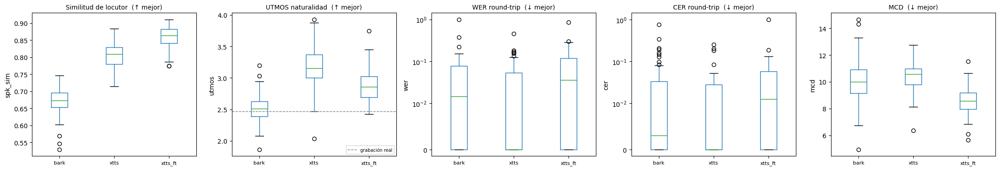

In [44]:
metrics = [("spk_sim", "Similitud de locutor  (↑ mejor)", False),
           ("utmos",   "UTMOS naturalidad  (↑ mejor)",    False),
           ("wer",     "WER round-trip  (↓ mejor)",       True),
           ("cer",     "CER round-trip  (↓ mejor)",       True),
           ("mcd",     "MCD  (↓ mejor)",                  False)]

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (col, title, log) in zip(axes, metrics):
    results.boxplot(column=col, by="backend", ax=ax, grid=False)
    ax.set_title(title, fontsize=10); ax.set_xlabel(""); ax.set_ylabel(col)
    ax.tick_params(axis="x", labelsize=8)
    if log:                                  # cola pesada: escala log
        ax.set_yscale("symlog", linthresh=0.01)

    # techo de referencia en UTMOS: las grabaciones reales
    if col == "utmos" and "utmos_ref" in results.columns:
        ax.axhline(results["utmos_ref"].mean(), ls="--", lw=1,
                   color="gray", label="grabación real")
        ax.legend(fontsize=7, loc="lower right")

plt.suptitle(""); plt.tight_layout(); plt.show()

## 12. Comparativas escuchando los audios generados

#### Audios de test por cada backend vs original

Se reproducen el **mejor** y el **peor** fragmento según la similitud de locutor del backend
clonador de referencia (`xtts_ft` si existe; si no, `xtts`), con el original al lado y las
métricas de cada backend. Escuchar los dos extremos da una idea honesta del rango de calidad.


In [45]:
from IPython.display import Audio, display

assert len(results) > 0, "no hay filas de test en results"

# Mejor y peor fragmento según la spk_sim del backend clonador de referencia
_rank_b = "xtts_ft" if (results["backend"] == "xtts_ft").any() else "xtts"
_ranked = (results[results["backend"] == _rank_b]
           .dropna(subset=["spk_sim"]).sort_values("spk_sim"))

for title, row0 in [("PEOR caso", _ranked.iloc[0]), ("MEJOR caso", _ranked.iloc[-1])]:
    frag_id = row0["id"]
    sub = results[results["id"] == frag_id]
    print("=" * 70)
    print(f"{title} según spk_sim de '{_rank_b}' — fragmento {frag_id}")
    print("TEXTO original:", sub["text"].iloc[0])
    print("\n· ORIGINAL:")
    display(Audio(sub["path"].iloc[0]))
    for _, row in sub.iterrows():            # una fila por backend para ese id
        print(f"\n· {row['backend']}  (spk_sim={row['spk_sim']}  wer={row['wer']}  mcd={row['mcd']})")
        print("  STT recon:", row["hyp"])
        display(Audio(row["recon_path"]))


PEOR caso según spk_sim de 'xtts_ft' — fragmento frag_0457
TEXTO original: Entonces verán, lo primero quiero que definamos es quién es N, quién es D, quién es D.

· ORIGINAL:



· xtts  (spk_sim=0.741  wer=0.059  mcd=10.58)
  STT recon: Entonces verán, lo primero quiero que definamos es quién N, quién es D, quién es D.



· bark  (spk_sim=0.671  wer=0.059  mcd=10.0)
  STT recon: Entonces verán, lo primero quiero que definamos es quién es M, quién es D, quién es D.



· xtts_ft  (spk_sim=0.774  wer=0.059  mcd=8.65)
  STT recon: Entonces, verán, lo primero que definamos es quién es N, quién es D, quién es D.


MEJOR caso según spk_sim de 'xtts_ft' — fragmento frag_0062
TEXTO original: El problema es que procesamos una palabra o un token a la vez o una, bueno para nosotros era un X en RN, o sea un montón de features que varían en el tiempo.

· ORIGINAL:



· xtts  (spk_sim=0.853  wer=0.029  mcd=9.98)
  STT recon: El problema es que procesamos una palabra o un token a la vez o una. Bueno para nosotros, era un X en RN. O sea, un montón de factures que varían en el tiempo.



· bark  (spk_sim=0.682  wer=0.029  mcd=9.64)
  STT recon: El problema es que procesamos una palabra o un token a la vez o una. Buena para nosotros era un X en RN, o sea un montón de features que varían en el tiempo.



· xtts_ft  (spk_sim=0.911  wer=0.118  mcd=8.94)
  STT recon: El problema es que procesamos una palabra o un token a vez o una... Bueno, para nosotros era un HSNL, o sea, un montón de features que varían en el tiempo.


## 13. Texto libre con la voz clonada (demo *deepfake*)

Aquí no hay audio original de referencia: se sintetiza una frase **inventada** con la voz clonada.
Evidencia lo fácil que es fabricar audio falso de un locutor con ~1 min de referencia. Como la
generación puede variar, se puede reejecutar la celda hasta obtener el audio deseado.

In [ ]:
# --- Reanudación para la demo (§13) ---
# Estas celdas re-establecen el estado mínimo para generar la demo tras reiniciar el kernel,
# sin repetir todo el pipeline: recuperan el checkpoint de fine-tuning desde disco, vuelven a
# registrar los backends y fijan el mejor checkpoint. Si el notebook se corrió entero, son un no-op.
FT_OUT = WORK_DIR / "xtts_ft_run"
SPEAKER_REF = WORK_DIR / "speaker_ref.wav"
# Si hace falta, recargar test tras un reinicio: test_df = pd.read_csv(WORK_DIR / "test.csv")
if globals().get("XTTS_FT_CKPT") is None and FT_OUT.exists():
    try:
        # Busca la carpeta de entrenamiento más reciente
        run_dir = max((p for p in FT_OUT.iterdir() if p.is_dir()), key=os.path.getmtime)

        # Vuelve a obtener el vocabulario (lo cargará instantáneamente desde el caché local)
        vocab_path = hf_hub_download("coqui/XTTS-v2", "vocab.json")

        # Reconstruye la variable global
        globals()["XTTS_FT_CKPT"] = {
            "checkpoint": str(run_dir / "best_model.pth"),
            "config": str(run_dir / "config.json"),
            "vocab": vocab_path
        }
        print(f"✅ Checkpoint fine-tuneado recuperado desde: {run_dir.name}")
    except Exception as e:
        print(f"⚠️ Error al recuperar el checkpoint de disco: {e}")

In [48]:
BACKEND_FNS = {}   # backend -> fn(text, out_path, speaker_ref)

# Ajustes de inferencia COMPARTIDOS por xtts y xtts_ft: la UNICA diferencia entre ambos
# debe ser el checkpoint, no estos knobs. Son los valores recomendados del XttsConfig v2
# (los best knobs de los autores); antes xtts los leia del config y xtts_ft heredaba los
# defaults del metodo (repetition_penalty=10, gpt_cond_len=6...), contaminando la comparacion.
XTTS_COND  = dict(gpt_cond_len=30, gpt_cond_chunk_len=4,
                  max_ref_length=30, sound_norm_refs=True)
XTTS_INFER = dict(temperature=0.75, length_penalty=1.0,
                  repetition_penalty=2.0, top_k=50, top_p=0.85)

def _xtts_fn_from_model(xtts_model):
    # Latentes de SPEAKER_REF + inference de BAJO NIVEL, con los mismos ajustes para los dos.
    gpt_cond, spk_emb = xtts_model.get_conditioning_latents(
        audio_path=[str(SPEAKER_REF)], **XTTS_COND)
    def fn(text, out, ref=None):
        o = xtts_model.inference(text, (LANGUAGE or "es"), gpt_cond, spk_emb, **XTTS_INFER)
        sf.write(str(out), o["wav"], 24000)
    return fn

def _register_xtts():
    from TTS.api import TTS
    # torch>=2.6 pone weights_only=True por defecto en torch.load y rompe la carga del checkpoint
    # de XTTS. Se registran las clases de config de XTTS como 'safe globals' para permitir cargarlo.
    try:
        from TTS.tts.configs.xtts_config import XttsConfig
        from TTS.tts.models.xtts import XttsAudioConfig, XttsArgs
        from TTS.config.shared_configs import BaseDatasetConfig
        torch.serialization.add_safe_globals([XttsConfig, XttsAudioConfig, XttsArgs, BaseDatasetConfig])
    except Exception:
        pass   # coqui-tts viejo (torch<2.6) no lo necesita
    m = TTS("tts_models/multilingual/multi-dataset/xtts_v2").to(DEVICE)
    return _xtts_fn_from_model(m.synthesizer.tts_model)   # modelo Xtts crudo, mismos knobs

def _register_bark():
    from transformers import AutoProcessor, BarkModel
    proc  = AutoProcessor.from_pretrained("suno/bark-small")
    model = BarkModel.from_pretrained("suno/bark-small").to(DEVICE)
    preset = f"v2/{(LANGUAGE or 'es')}_speaker_1"
    def fn(text, out, ref=None):   # ref ignorada: Bark no clona
        inp = {k: v.to(DEVICE) for k, v in proc(text, voice_preset=preset).items()}
        arr = model.generate(**inp).cpu().numpy().squeeze()
        sf.write(str(out), arr, model.generation_config.sample_rate)
    return fn


def _register_xtts_ft():
    ckpt = globals().get("XTTS_FT_CKPT")
    if not ckpt:
        raise RuntimeError("no hay checkpoint fine-tuneado; corre la celda de fine-tuning con RUN_XTTS_FINETUNE=True")
    from TTS.tts.configs.xtts_config import XttsConfig
    from TTS.tts.models.xtts import Xtts
    cfg = XttsConfig(); cfg.load_json(ckpt["config"])
    model = Xtts.init_from_config(cfg)
    model.load_checkpoint(cfg, checkpoint_path=ckpt["checkpoint"],
                          vocab_path=ckpt["vocab"], use_deepspeed=False)
    model.to(DEVICE)
    # MISMA referencia y MISMOS ajustes que el zero-shot: solo cambian los pesos del checkpoint.
    return _xtts_fn_from_model(model)

REGISTRY = {"xtts": _register_xtts, "xtts_ft": _register_xtts_ft, "bark": _register_bark}

# xtts siempre; xtts_ft solo si existe checkpoint. Anade "bark","tortoise","chattts","openvoice".
ACTIVE_BACKENDS = ["xtts", "bark"]

if globals().get("XTTS_FT_CKPT"):
    ACTIVE_BACKENDS.append("xtts_ft")

for b in ACTIVE_BACKENDS:
    try:
        BACKEND_FNS[b] = REGISTRY[b]()
        print("backend listo:", b)
    except Exception as e:
        print(f"[!] no se pudo cargar '{b}': {e}")


backend listo: xtts
backend listo: bark
backend listo: xtts_ft


In [49]:
# (Reanudación) Igual que en §8: fija xtts_ft al checkpoint elegido por métricas (checkpoint_280).
BEST_CK = run_dir / "checkpoint_280.pth"
XTTS_FT_CKPT["checkpoint"] = str(BEST_CK)
BACKEND_FNS["xtts_ft"] = _register_xtts_ft()
print("xtts_ft ahora usa:", Path(XTTS_FT_CKPT["checkpoint"]).name)

# Limpia los wav de val del barrido
for p in RECON_DIR.glob("xtts_ft_*.wav"): p.unlink()

xtts_ft ahora usa: checkpoint_280.pth


In [50]:
#Evitar warnings de padding del XTTs zero shot (usa GPT internamente)
transformers.logging.set_verbosity_error()

In [53]:
from IPython.display import Audio, display

MY_TEXT = "Hola chicos, solamente quería decirles que están exonerados todos del curso y no deben presentar ningún deber ni proyecto."
FREE_DIR = RECON_DIR / "free_text"
FREE_DIR.mkdir(parents=True, exist_ok=True)

print("TEXTO:", MY_TEXT, "\n")
for backend, fn in BACKEND_FNS.items():
    out = FREE_DIR / f"{backend}_free.wav"
    try:
        fn(MY_TEXT, out, str(SPEAKER_REF))
        print(f"· {backend}:")
        display(Audio(str(out)))
    except Exception as e:
        print(f"[err] {backend}: {e}")

TEXTO: Hola chicos, solamente quería decirles que están exonerados todos del curso y no deben presentar ningún deber ni proyecto. 

· xtts:


· bark:


· xtts_ft:


## 14. Conclusiones
* La clonación de voz es hoy viable y plantea un problema real de seguridad. Bark tarda ~10 s por
  inferencia en el servidor; XTTS, con su GPT autorregresivo (next-token prediction), lo hace en
  segundos, acercando el riesgo de clonación en tiempo casi real.
* Para clonar mejor conviene reconstruir **a trozos (chunking)**: la prosodia de cada frase la
  fijan los tokens cercanos, y en frases largas el self-attention arrastra contexto innecesario de
  los primeros tonos al timbre de la oración actual.
* Las métricas no tienen la verdad absoluta sobre si una voz es de una persona. Se ve en el
  clustering: fragmentos válidos del locutor salen del clúster y dentro quedan fragmentos donde en
  alguna parte suena otra voz.
* El fine-tuning de XTTS, aunque baja poco la loss, mejora bastante la fonética, el vocabulario y
  sobre todo el timbre (+0.055 de spk_sim y −1.8 de MCD en el análisis pareado), a un pequeño
  coste de inteligibilidad (WER) y naturalidad (UTMOS): se adapta también al canal ruidoso de Zoom.
* Lo que más asegura la clonación en XTTS es el **audio de referencia**: una referencia bien
  tratada y de calidad validada genera mejores tokens de audio del locutor.

## 15. Trabajo futuro
* Reducir el overfitting del fine-tuning con data augmentation (validando su efecto sobre el
  modelo preentrenado) u otras formas de generar muestras nuevas a partir de las reales.
* Validar los datos del fine-tuning: otras longitudes de clip (min–max) u otro recorte distinto a
  Silero VAD.
* Estudiar la influencia del batch size y de otros hiperparámetros sobre métricas y overfitting.
* Buscar sistemáticamente los mejores hiperparámetros de inferencia (top_k, top_p, temperature,
  max_audio_len, conditioning_len): cambian drásticamente entre una buena clonación y una "voz
  robot".
* Estudiar la longitud y calidad óptimas del audio de referencia y su preprocesamiento.
* Probar otros modelos de clonación de voz y comparar calidad y tiempos.